# **Stochastic Processes and Simulation in Natural Sciences Project**
### Bocconi University, May 2024

- **Elisavet Machaira**(ID:3152697)
- **Mariami Alavidze** (ID:3177419)
- **Luiza Zinca**      (ID:3168376)

# Escape of a Particle from an Intracellular Region #

### Simulating the Brownian motion of a particle in a 2D circular domain with an exit segment and investigate the mean exit time as a function of the segment’s angular width theta ###

## Mathematical Background: Overview of Brownian Motion and the Setup for the Exit Time Calculation

### Brownian Motion
Brownian motion, named after the botanist Robert Brown, describes the random motion of particles suspended in a fluid resulting from their collision with fast-moving molecules in the fluid. In mathematical terms, Brownian motion is a type of stochastic process that models the random movement of a particle in a continuous space and time.

A two-dimensional Brownian motion $(\mathbf{B}(t) = (B_x(t), B_y(t)))$ is characterized by:
- The process starts at the origin: $( \mathbf{B}(0) = (0,0) )$.
- It has independent increments: the displacements of the particle over non-overlapping time intervals are independent.
- The increments are normally distributed: $B_x(t + \Delta t) - B_x(t) \sim \mathcal{N}(0, 2D \Delta t)$ and 
$B_y(t + \Delta t) - B_y(t) \sim \mathcal{N}(0, 2D \Delta t)$, where \( D \) is the diffusion coefficient and $( \Delta t )$ is a small time increment.

### Setup for the Exit Time Calculation
We consider a particle undergoing Brownian motion within a two-dimensional circular domain of radius $( r )$. The particle starts at the center of the circle and can exit the domain through an opening defined by a segment of the circle with an angular width $( \theta )$.

#### Domain and Exit Region
- **Domain**: The circular domain is defined by $( x^2 + y^2 < r^2 )$.
- **Exit Region**: The exit region is a segment of the circle, defined by the angular range $( -\theta/2 \leq \phi \leq \theta/2 )$, where $( \phi )$ is the angle measured from the positive $( x )$-axis.

#### Mean Exit Time
The mean exit time $( \langle T \rangle )$ is the expected time it takes for the particle to exit the domain through the specified exit region. This can be calculated by simulating the Brownian motion of the particle and recording the time it takes to reach the exit region in each simulation. By averaging these exit times over many simulations, we obtain an estimate of the mean exit time as a function of the angular width $( \theta )$.

#### Simulation Approach
1. **Initialization**: The particle starts at the origin $((0,0))$.
2. **Time Evolution**: At each time step $( \Delta t )$, the particle's position is updated according to the Brownian motion equations:
   $[
   x(t + \Delta t) = x(t) + \sqrt{2D \Delta t} \, \eta_x, \quad y(t + \Delta t) = y(t) + \sqrt{2D \Delta t} \, \eta_y
   ]$
   where $( \eta_x )$ and $( \eta_y )$ are independent standard normal random variables.
3. **Boundary Check**: After updating the position, check if the particle has exited the circular domain. If the particle's position $( (x, y) )$ satisfies $( x^2 + y^2 \geq r^2 )$, check if it lies within the exit region by calculating the angle $( \phi = \arctan2(y, x) )$. If $( -\theta/2 \leq \phi \leq \theta/2 )$, record the exit time.
4. **Repeat**: Repeat the above steps for a large number of simulations to obtain a distribution of exit times.
5. **Average**: Compute the mean exit time $( \langle T \rangle )$ from the distribution of exit times.

This simulation-based approach allows us to explore how the mean exit time varies with the angular width $( \theta )$, providing insights into the behavior of the system under different geometric constraints.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# simulation parameters
r = 1.0  # radius of the circular domain
D = 1.0  # diffusion coefficient
dt = 0.01  # time step
num_simulations = 1000  # number of simulations for averaging

In [3]:
# function to check if particle is outside the domain
def is_outside(x, y, r):
    return x**2 + y**2 >= r**2

In [4]:
# function to check if particle is in the exit region
def is_in_exit_region(x, y, theta):
    angle = np.arctan2(y, x)
    return -theta/2 <= angle <= theta/2

Note at this point that setting the starting position at the center is a common and reasonable practice since it leverages the symmetry of the circular domain, making the problem simpler and more intuitive. The center is the point that is maximally distant from the boundary in all directions, ensuring that the particle has to traverse some distance before potentially exiting, which is useful for studying exit times. This choice further provides a consistent initial condition across all simulations, allowing for more straightforward comparisons between different scenarios or parameter values.

In [5]:
# function to simulate Brownian motion and compute exit time
def simulate_exit_time(r, theta, D, dt):
    x, y = 0, 0
    t = 0  # starting time
    while True:
        # update position based on Brownian motion
        x += np.sqrt(2 * D * dt) * np.random.randn()
        y += np.sqrt(2 * D * dt) * np.random.randn()
        t += dt
        if is_outside(x, y, r):
            if is_in_exit_region(x, y, theta):
                return t
            else:
                x, y = 0, 0  # reset position to center

In [6]:
# the main simulation loop
thetas = np.linspace(0.1, np.pi, 10)  # different theta values to investigate
mean_exit_times = []

for theta in thetas:
    exit_times = []
    for _ in range(num_simulations):
        exit_time = simulate_exit_time(r, theta, D, dt)
        exit_times.append(exit_time)
    mean_exit_times.append(np.mean(exit_times))

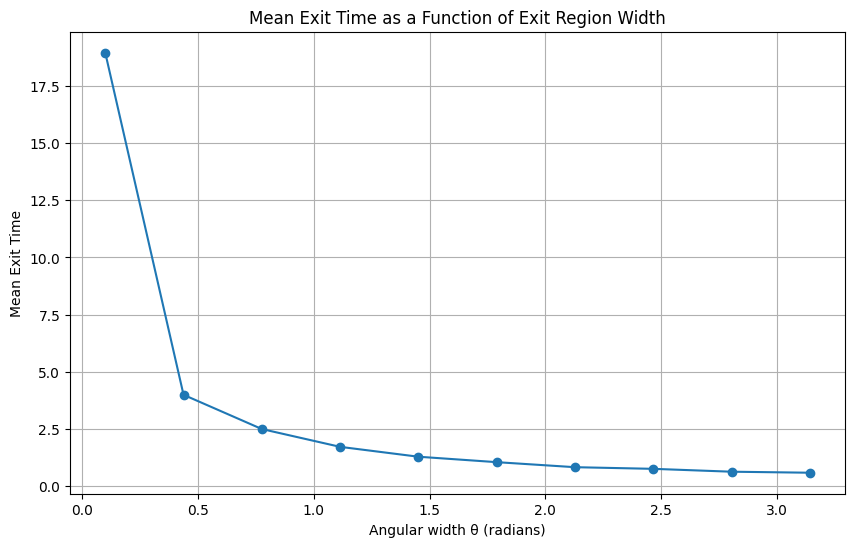

In [7]:
# Plotting the results
plt.figure(figsize=(10, 6))
plt.plot(thetas, mean_exit_times, marker='o')
plt.xlabel('Angular width θ (radians)')
plt.ylabel('Mean Exit Time')
plt.title('Mean Exit Time as a Function of Exit Region Width')
plt.grid(True)
plt.show()

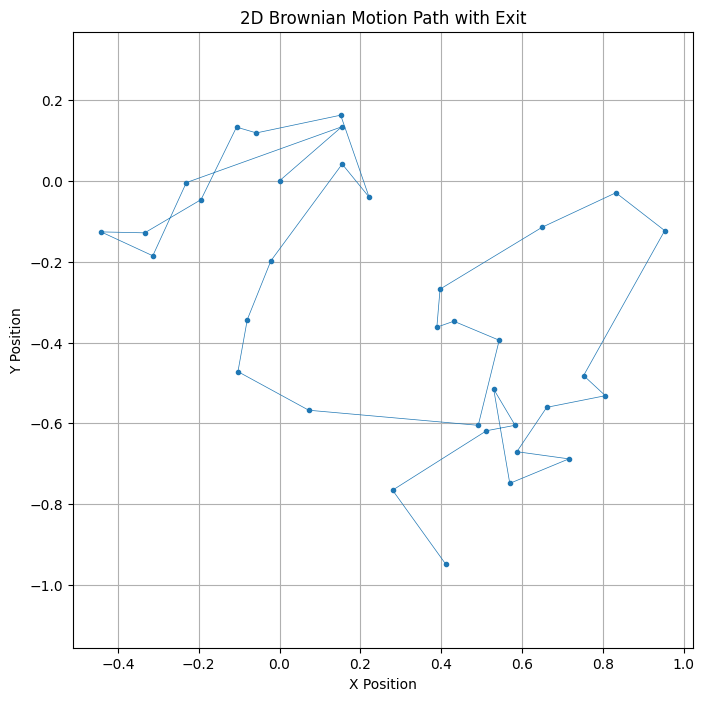

Exit time: 1.1000000000000008


In [8]:
# function to simulate Brownian motion and compute exit time - adapted version which also plots the motion so 2 birds with 1 stone 
def simulate_exit_time_and_path(r, theta, D, dt):
    x, y = 0, 0  # starting position at the center
    t = 0  # starting time
    x_coord = [x]  # list to track x coordinates
    y_coord = [y]
    while True:
        # update position based on Brownian motion
        x += np.sqrt(2 * D * dt) * np.random.randn()
        y += np.sqrt(2 * D * dt) * np.random.randn()
        x_coord.append(x)
        y_coord.append(y)
        t += dt
        if is_outside(x, y, r):
            if is_in_exit_region(x, y, theta):
                return t, x_coord, y_coord
            else:
                x, y = 0, 0  # reset position to center
                x_coord = [x]
                y_coord = [y]

exit_time, path_x, path_y = simulate_exit_time_and_path(r, theta, D, dt)

plt.figure(figsize=(8, 8))
plt.plot(path_x, path_y, marker='o', markersize=3, linewidth=0.5)
plt.title('2D Brownian Motion Path with Exit')
plt.xlabel('X Position')
plt.ylabel('Y Position')
plt.grid(True)
plt.axis('equal')  
plt.show()

print("Exit time:", exit_time)

We investigate how the mean exit time depends on the angular width θ of the exit region. 

The results show that as the angular width θ increases, the mean exit time decreases. This is because a larger exit region increases the probability of the particle exiting the domain, thus reducing the mean exit time.

Now we want to use the following function that takes the number of paths, number of steps, time step, and diffusion coefficient as parameters to simulate multiple Brownian motion paths and plot them on a 2D plane. Each path is represented by a different color for better visualization.

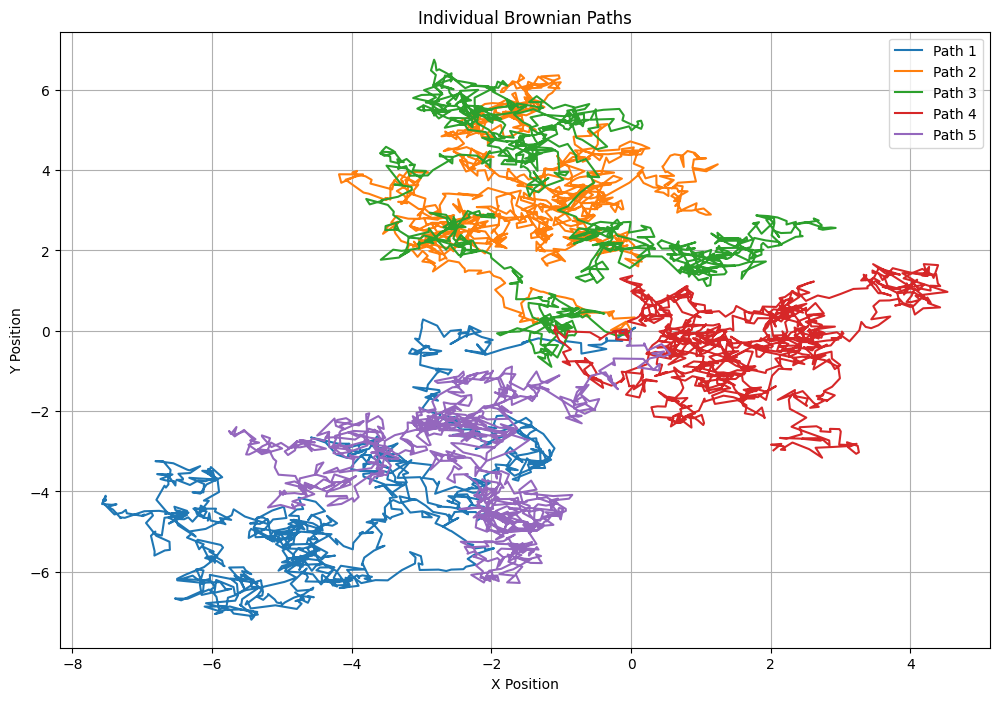

In [9]:
# Define the function to simulate and plot individual Brownian paths
def simulate_brownian_paths(num_paths, num_steps, dt, D):
    plt.figure(figsize=(12, 8))
    
    for i in range(num_paths):
        # Initial position
        x, y = [0], [0]
        
        # Simulate Brownian motion
        for _ in range(num_steps):
            dx = np.sqrt(2 * D * dt) * np.random.randn()
            dy = np.sqrt(2 * D * dt) * np.random.randn()
            x.append(x[-1] + dx)
            y.append(y[-1] + dy)
        
        plt.plot(x, y, label=f'Path {i+1}')
    
    plt.xlabel('X Position')
    plt.ylabel('Y Position')
    plt.title('Individual Brownian Paths')
    plt.legend()
    plt.grid(True)
    plt.show()

# Parameters
num_paths = 5      # Number of paths to simulate
num_steps = 1000   # Number of steps in each path
dt = 0.01          # Time step
D = 1.0            # Diffusion coefficient

# Simulate and plot Brownian paths
simulate_brownian_paths(num_paths, num_steps, dt, D)


Brownian motion, being a stochastic process, is, by its very nature, characterized by random and unpredictable particle trajectories. This inherent randomness is a fundamental aspect of the phenomenon, driven by the incessant collisions of particles with molecules in the surrounding medium. Throughout our analysis, the impact of this randomness is evident.

### Configuration of Particles with Brownian Motion Inside a Boundary ###

In [99]:
def simulate_brownian_motion(num_steps, dt, radius, theta, num_particles, boundary_type='reflecting'):
    positions = np.zeros((num_particles, 2))
    inside_domain = lambda x, y: x**2 + y**2 <= radius**2
    exit_region = lambda x, y: np.arctan2(y, x) < theta/2 and np.arctan2(y, x) > -theta/2
    
    for step in range(num_steps):
        for i in range(num_particles):
            angle = 2 * np.pi * np.random.rand()
            step_size = np.sqrt(2 * dt) * np.random.randn()
            positions[i] += step_size * np.array([np.cos(angle), np.sin(angle)])
            
            if not inside_domain(positions[i][0], positions[i][1]):
                if boundary_type == 'reflecting':
                    # Reflecting boundary: move back inside
                    while not inside_domain(positions[i][0], positions[i][1]):
                        positions[i] -= step_size * np.array([np.cos(angle), np.sin(angle)])
                        angle = 2 * np.pi * np.random.rand()
                        step_size = np.sqrt(2 * dt) * np.random.randn()
                        positions[i] += step_size * np.array([np.cos(angle), np.sin(angle)])
                elif boundary_type == 'absorbing':
                    # Absorbing boundary: reset position to origin
                    positions[i] = np.zeros(2)
                    
            if boundary_type == 'absorbing' and exit_region(positions[i][0], positions[i][1]):
                positions[i] = np.zeros(2)
    
    return positions

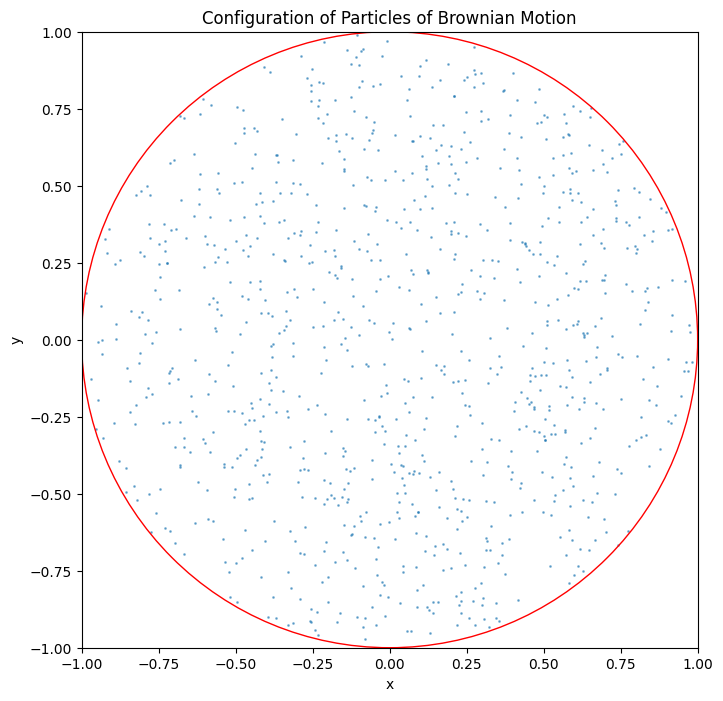

In [100]:
def plot_distribution(positions, radius):
    plt.figure(figsize=(8, 8))
    plt.scatter(positions[:, 0], positions[:, 1], alpha=0.5, s=1)
    circle = plt.Circle((0, 0), radius, color='r', fill=False)
    plt.gca().add_artist(circle)
    plt.xlim([-radius, radius])
    plt.ylim([-radius, radius])
    plt.gca().set_aspect('equal', adjustable='box')
    plt.title("Configuration of Particles of Brownian Motion")
    plt.xlabel("x")
    plt.ylabel("y")
    plt.show()

# Parameters
num_steps = 10000
dt = 0.01
radius = 1.0
theta = np.pi / 4  # 45 degrees
num_particles = 1000
boundary_type = 'reflecting'  # 'reflecting' or 'absorbing'

positions = simulate_brownian_motion(num_steps, dt, radius, theta, num_particles, boundary_type)
plot_distribution(positions, radius)

The particles are uniformly distributed within the circular domain. This suggests that, given enough time, the particles explore the entire domain uniformly due to the random nature of Brownian motion and the reflecting boundaries ensuring they stay within the domain.

### Exploring the Stationary Distribution ###

### Varying the Parameters ###

We can analyze how different values of the diffusion coefficient affect the mean exit time.

In [48]:
def simulate_exit_time(r, theta, D, dt):
    x, y = 0, 0
    t = 0  # starting time
    while True:
        # update position based on Brownian motion
        x += np.sqrt(2 * D * dt) * np.random.randn()
        y += np.sqrt(2 * D * dt) * np.random.randn()
        t += dt
        if is_outside(x, y, r):
            if is_in_exit_region(x, y, theta):
                return t
            else:
                x, y = 0, 0

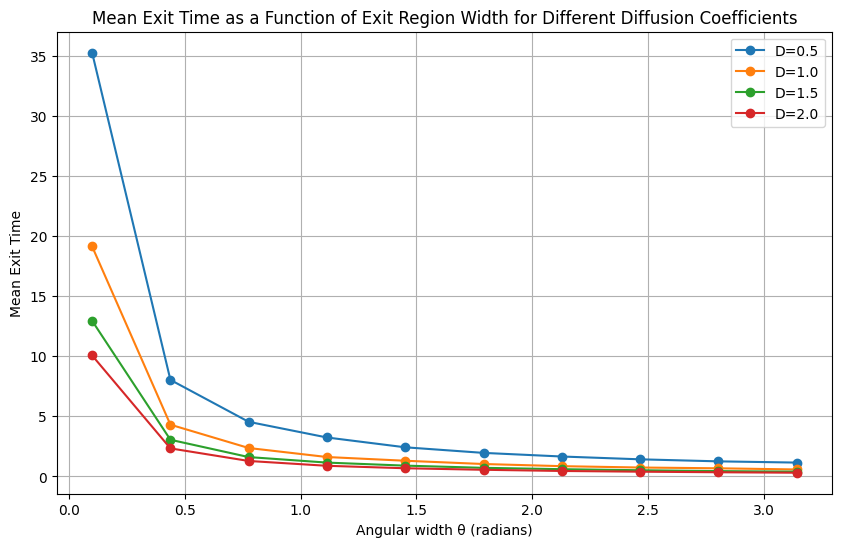

In [45]:
# effect of different diffusion coefficients on the mean exit time
diffusion_coefficients = [0.5, 1.0, 1.5, 2.0]
results = {}

for D in diffusion_coefficients:
    mean_exit_times = []
    for theta in thetas:
        exit_times = []
        for _ in range(num_simulations):
            exit_time = simulate_exit_time(r, theta, D, dt)
            exit_times.append(exit_time)
        mean_exit_times.append(np.mean(exit_times))
    results[D] = mean_exit_times

plt.figure(figsize=(10, 6))
for D, times in results.items():
    plt.plot(thetas, times, marker='o', label=f'D={D}')
plt.xlabel('Angular width θ (radians)')
plt.ylabel('Mean Exit Time')
plt.title('Mean Exit Time as a Function of Exit Region Width for Different Diffusion Coefficients')
plt.legend()
plt.grid(True)
plt.show()


The mean exit time decreases sharply with increasing θ up to 0.5 radians and stabilizes beyond this point, regardless of the diffusion coefficient.

Higher diffusion coefficients generally lead to lower mean exit times, with the most significant differences observed for small θ values.

The optimal exit region width for minimizing exit times is around 0.5 radians for all diffusion coefficients studied.

With interest in performing some further sensitivity analysis of our model we, first, modify the parameters slightly and observe the effects on the mean exit times.

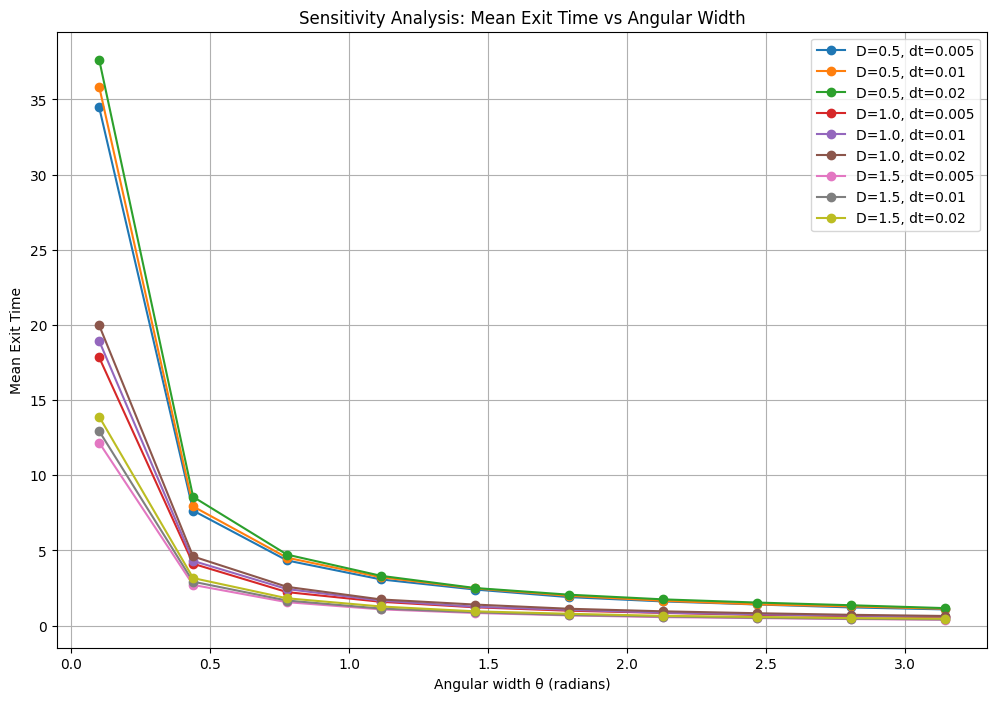

In [49]:
# different diffusion coefficients and time steps
diffusion_coefficients = [0.5, 1.0, 1.5]
time_steps = [0.005, 0.01, 0.02]

plt.figure(figsize=(12, 8))
for D in diffusion_coefficients:
    for dt in time_steps:
        mean_exit_times = []
        for theta in thetas:
            exit_times = [simulate_exit_time(r, theta, D, dt) for _ in range(num_simulations)]
            mean_exit_times.append(np.mean(exit_times))
        plt.plot(thetas, mean_exit_times, marker='o', label=f'D={D}, dt={dt}')

plt.xlabel('Angular width θ (radians)')
plt.ylabel('Mean Exit Time')
plt.title('Sensitivity Analysis: Mean Exit Time vs Angular Width')
plt.legend()
plt.grid(True)
plt.show()

The mean exit time decreases sharply with increasing θ up to 0.5 radians and stabilizes beyond this point, regardless of the diffusion coefficient or time step.

Lower diffusion coefficients (D = 0.5) result in higher mean exit times across all θ values, as lower D indicates slower particle movement, leading to longer exit times.

Higher diffusion coefficients (D = 1.0 and 1.5) result in lower mean exit times, indicating that particles move faster and are more likely to find the exit sooner.

The time step (dt) does not significantly impact the overall trend of mean exit times for different θ values.

There is some variability in mean exit times for smaller θ values (θ < 0.5 radians), but this variability is relatively small compared to the impact of the diffusion coefficient. Higher diffusion coefficients generally lead to lower mean exit times, with the most significant differences observed for small θ values.

We compare the exit times for two different diffusion coefficients using a t-test.

In [50]:
import scipy.stats
from scipy.stats import ttest_ind

# Simulate exit times for two different diffusion coefficients
D1, D2 = 1.0, 1.5
theta = np.pi / 4  # Example theta value

exit_times_D1 = [simulate_exit_time(r, theta, D1, dt) for _ in range(num_simulations)]
exit_times_D2 = [simulate_exit_time(r, theta, D2, dt) for _ in range(num_simulations)]

# Perform t-test
t_stat, p_value = ttest_ind(exit_times_D1, exit_times_D2)
print(f"T-statistic: {t_stat:.2f}, P-value: {p_value:.2e}")

T-statistic: 17.96, P-value: 4.88e-71


Comparing exit times for different diffusion coefficients helps us in understanding how diffusion impacts the process. If the t-test shows a significant difference, it indicates that the diffusion coefficient plays a critical role in determining exit times.

In our case the T-test statistic, which measures the size of the difference relative to the variation in your sample data, has a relatively high absolute value indicating a more significant difference. This, combined with our p-value <0.05 suggests that the observed difference is unlikely due to chance, leading to the rejection of the null hypothesis, which for us is that there is no significant difference in the exit times between the two diffusion coefficients.

The high t-statistic and extremely low p-value suggest that the difference in exit times is not only statistically significant but also practically significant.

The results strongly indicate that the diffusion coefficient significantly impacts the exit times.

We fit a linear regression model to the mean exit times as a function of theta as a useful baseline model.

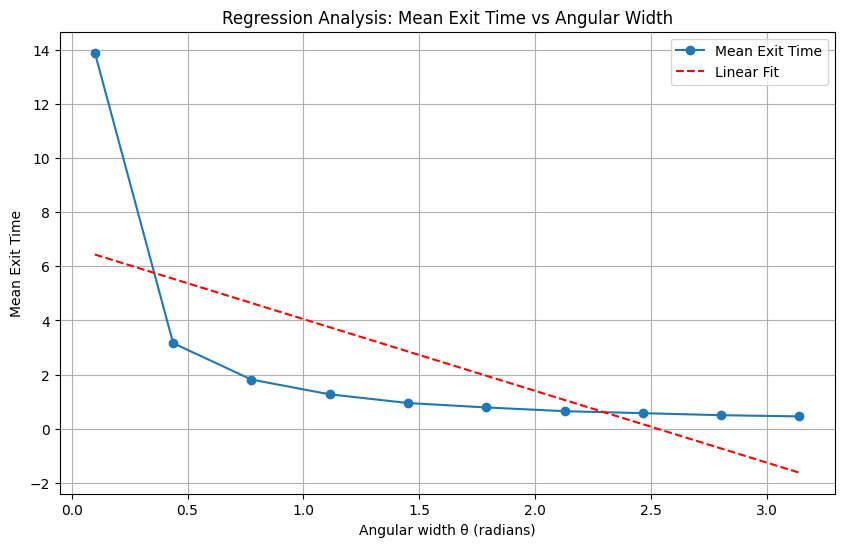

R-squared: 0.43


In [51]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

# prepare data for regression
X = thetas.reshape(-1, 1)
y = mean_exit_times

# fit linear regression model
model = LinearRegression()
model.fit(X, y)

y_pred = model.predict(X)

plt.figure(figsize=(10, 6))
plt.plot(thetas, mean_exit_times, marker='o', label='Mean Exit Time')
plt.plot(thetas, y_pred, linestyle='--', color='r', label='Linear Fit')
plt.xlabel('Angular width θ (radians)')
plt.ylabel('Mean Exit Time')
plt.title('Regression Analysis: Mean Exit Time vs Angular Width')
plt.legend()
plt.grid(True)
plt.show()

r2 = r2_score(y, y_pred)
print(f"R-squared: {r2:.2f}")


This initial regression analysis helps to understand the nature of the relationship between the independent variable (theta) and the dependent variable (mean exit time) in order to provide insights into how changes in theta affect the mean exit time.

From the relatively low R-squared value we can see that the model is not the best fit. The relationship between mean exit time and angular width (θ) is clearly non-linear, characterized by a sharp initial decrease and a stabilization phase. A linear model is insufficient to capture this behavior accurately.

### Statistical Analysis ###

Instead of just looking at the mean exit time, we can analyze the distribution of exit times for different 𝜃 by plotting histograms or probability density functions (PDFs).

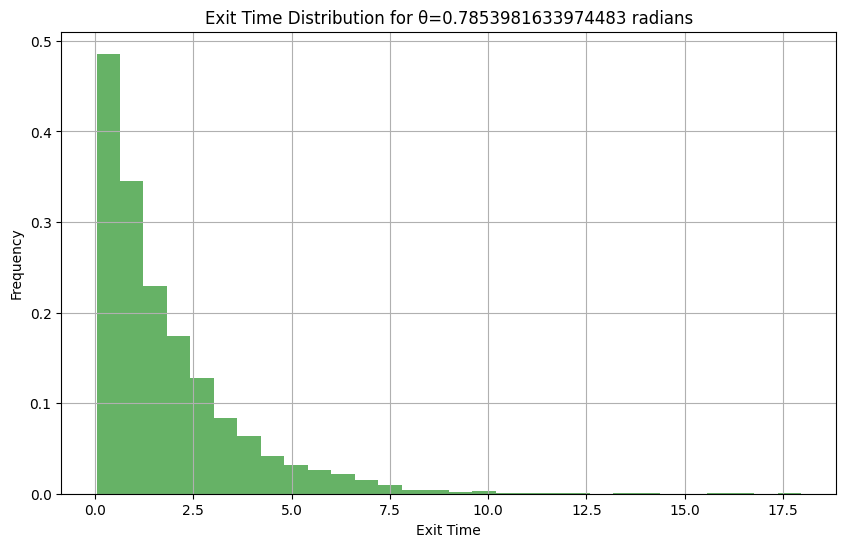

In [52]:
# plotting the distribution of exit times for a specific theta
theta = np.pi / 4  # example theta value
exit_times = [simulate_exit_time(r, theta, D, dt) for _ in range(num_simulations)]

plt.figure(figsize=(10, 6))
plt.hist(exit_times, bins=30, density=True, alpha=0.6, color='g')
plt.xlabel('Exit Time')
plt.ylabel('Frequency')
plt.title(f'Exit Time Distribution for θ={theta} radians')
plt.grid(True)
plt.show()

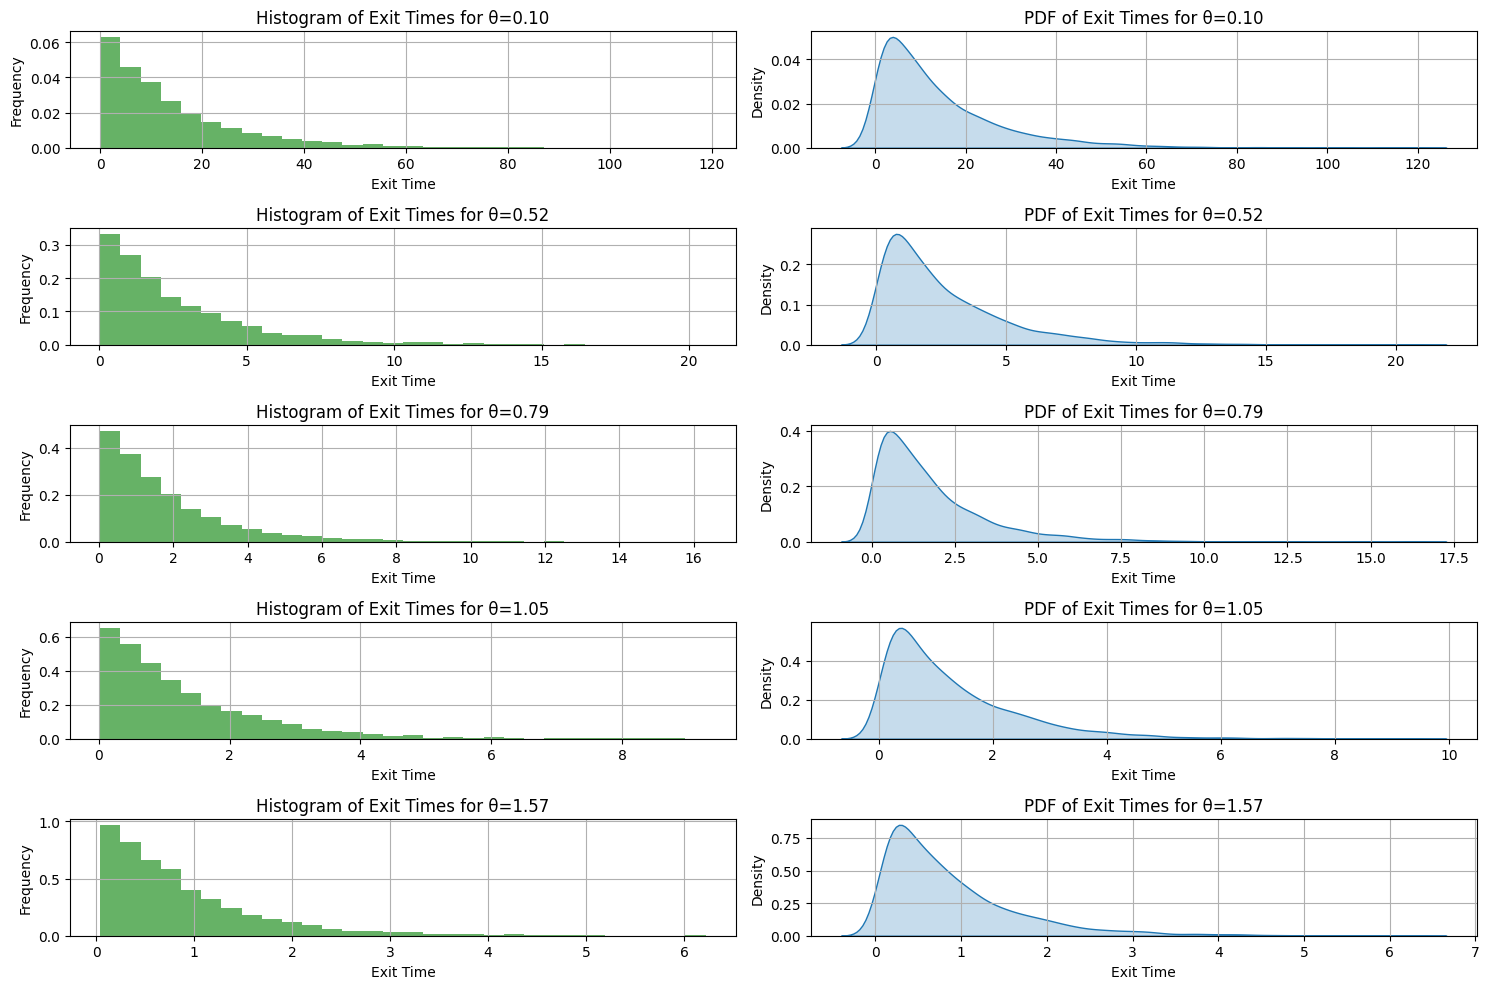

In [53]:
import seaborn as sns

# function to plot histogram and PDF for exit times
def plot_exit_time_distribution(thetas, num_simulations, r, D, dt):
    plt.figure(figsize=(15, 10))
    for i, theta in enumerate(thetas):
        exit_times = [simulate_exit_time(r, theta, D, dt) for _ in range(num_simulations)]
        
        # histogram
        plt.subplot(len(thetas), 2, 2*i+1)
        plt.hist(exit_times, bins=30, density=True, alpha=0.6, color='g')
        plt.xlabel('Exit Time')
        plt.ylabel('Frequency')
        plt.title(f'Histogram of Exit Times for θ={theta:.2f}')
        plt.grid(True)
        
        # PDF using kernel density estimation
        plt.subplot(len(thetas), 2, 2*i+2)
        sns.kdeplot(exit_times, bw_adjust=1.0, fill=True)
        plt.xlabel('Exit Time')
        plt.ylabel('Density')
        plt.title(f'PDF of Exit Times for θ={theta:.2f}')
        plt.grid(True)
    
    plt.tight_layout()
    plt.show()

thetas_example = [0.1, np.pi/6, np.pi/4, np.pi/3, np.pi/2]  # example theta values
plot_exit_time_distribution(thetas_example, num_simulations, r, D, dt)

As the angular width (θ) increases, the shape and spread of the distributions change.

As the angular width θ of the exit region increases, the mean exit time decreases, and the distribution of exit times becomes more concentrated around shorter values.This implies that particles exit more quickly and consistently with wider exit regions.

Narrow exit regions (small θ) lead to more spread and longer exit times.Whereas, wider exit regions (large θ) result in shorter and less variable exit times.

We can also calculate the confidence intervals for the mean exit time in order to provide a statistical measure of the uncertainty in our estimates. 

A 95% confidence interval for mean exit time provides a range within which we expect the true mean exit time to lie with 95% confidence, meaning that, if we were to repeat the simulations many times and compute the mean exit time and its confidence interval each time, we would expect the true mean exit time to lie within these intervals 95% of the time.

In [54]:
import scipy.stats as stats

# calculate confidence intervals for the mean exit time
confidence_level = 0.95
for theta in thetas:
    exit_times = [simulate_exit_time(r, theta, D, dt) for _ in range(num_simulations)]
    mean_exit_time = np.mean(exit_times)
    confidence_interval = stats.t.interval(confidence_level, len(exit_times)-1, loc=mean_exit_time, scale=stats.sem(exit_times))
    print(f"Theta: {theta:.2f}, Mean Exit Time: {mean_exit_time:.2f}, 95% CI: {confidence_interval}")

Theta: 0.10, Mean Exit Time: 13.90, 95% CI: (13.510859191430791, 14.28605280856918)
Theta: 0.44, Mean Exit Time: 3.24, 95% CI: (3.152886655219932, 3.3289773447800313)
Theta: 0.78, Mean Exit Time: 1.77, 95% CI: (1.7272864626809965, 1.8224895373189987)
Theta: 1.11, Mean Exit Time: 1.28, 95% CI: (1.246821756423946, 1.3142342435760532)
Theta: 1.45, Mean Exit Time: 0.96, 95% CI: (0.9369982124650932, 0.9868257875349077)
Theta: 1.79, Mean Exit Time: 0.78, 95% CI: (0.7618311526753782, 0.8009208473246227)
Theta: 2.13, Mean Exit Time: 0.67, 95% CI: (0.6555818179118513, 0.6893781820881493)
Theta: 2.47, Mean Exit Time: 0.56, 95% CI: (0.5506586875809634, 0.5789893124190371)
Theta: 2.80, Mean Exit Time: 0.51, 95% CI: (0.4940890793417915, 0.5191429206582088)
Theta: 3.14, Mean Exit Time: 0.45, 95% CI: (0.4377017378952435, 0.45978626210475676)


As the value of θ increases we can notice the CI becoming narrower indicating more precise estimates of the mean exit time since there is less variability in the exit times across simulations. It is also worth noticing that no two confidence intervals overlap which shows that there are statistically significant differences between the mean exit times for the different theta values we are examining.

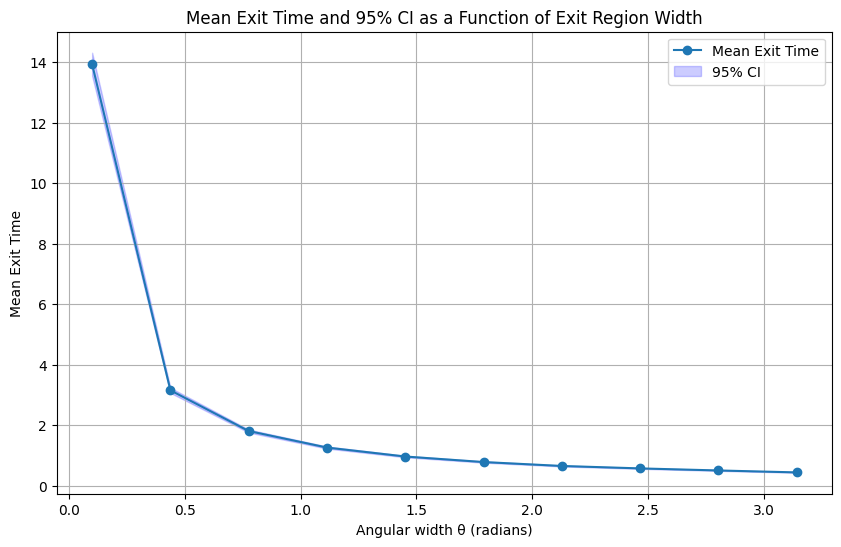

In [56]:
# main simulation loop to calculate mean exit times and 95% CIs
thetas = np.linspace(0.1, np.pi, 10)  # different theta values to investigate
mean_exit_times = []
confidence_intervals = []

for theta in thetas:
    exit_times = [simulate_exit_time(r, theta, D, dt) for _ in range(num_simulations)]
    mean_exit_time = np.mean(exit_times)
    confidence_interval = stats.t.interval(0.95, len(exit_times)-1, loc=mean_exit_time, scale=stats.sem(exit_times))
    mean_exit_times.append(mean_exit_time)
    confidence_intervals.append(confidence_interval)

# extract lower and upper bounds of the confidence intervals
ci_lower = [ci[0] for ci in confidence_intervals]
ci_upper = [ci[1] for ci in confidence_intervals]

# plot mean exit times with 95% confidence intervals
plt.figure(figsize=(10, 6))
plt.plot(thetas, mean_exit_times, marker='o', label='Mean Exit Time')
plt.fill_between(thetas, ci_lower, ci_upper, color='b', alpha=0.2, label='95% CI')
plt.xlabel('Angular width θ (radians)')
plt.ylabel('Mean Exit Time')
plt.title('Mean Exit Time and 95% CI as a Function of Exit Region Width')
plt.legend()
plt.grid(True)
plt.show()

Relatively wider confidence intervals for smaller θ values indicate higher variability, while narrower intervals for larger θ values reflect more stable exit times.

### Optimal Exit Width ###

In [57]:
from scipy.optimize import curve_fit

# main simulation loop to find optimal exit width
thetas = np.linspace(0.01, np.pi, 50)  # finer grid of theta values to investigate
mean_exit_times = []

for theta in thetas:
    exit_times = []
    for _ in range(num_simulations):
        exit_time = simulate_exit_time(r, theta, D, dt)
        exit_times.append(exit_time)
    mean_exit_times.append(np.mean(exit_times))

In [58]:
# identify the optimal theta
optimal_index = np.argmin(mean_exit_times)
theta_opt = thetas[optimal_index]
mean_exit_time_opt = mean_exit_times[optimal_index]

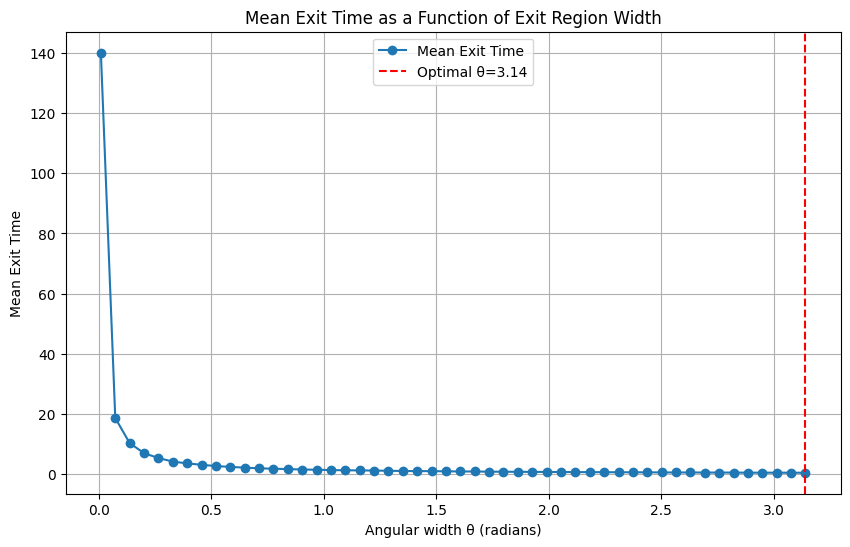

The optimal angular width θ is 3.14 radians with a mean exit time of 0.45 time units.


In [59]:
plt.figure(figsize=(10, 6))
plt.plot(thetas, mean_exit_times, marker='o', label='Mean Exit Time')
plt.axvline(theta_opt, color='r', linestyle='--', label=f'Optimal θ={theta_opt:.2f}')
plt.xlabel('Angular width θ (radians)')
plt.ylabel('Mean Exit Time')
plt.title('Mean Exit Time as a Function of Exit Region Width')
plt.legend()
plt.grid(True)
plt.show()

print(f"The optimal angular width θ is {theta_opt:.2f} radians with a mean exit time of {mean_exit_time_opt:.2f} time units.")

### Curve Fitting ###

Very simply, curve fitting is the process of constructing a curve, or mathematical function, that has the best fit to a series of data points. In our case, we can use curve fitting to get a more precise estimate of the optimal theta.

In [60]:
def parabolic_fit(theta, a, b, c):
    return a * theta**2 + b * theta + c

params, _ = curve_fit(parabolic_fit, thetas, mean_exit_times)
a, b, c = params
theta_opt_fit = -b / (2 * a)

print(f"Refined optimal angular width θ using curve fitting: {theta_opt_fit:.2f} radians.")

Refined optimal angular width θ using curve fitting: 1.95 radians.


What if we also examine different curve fitting models and discuss their goodness of fit?

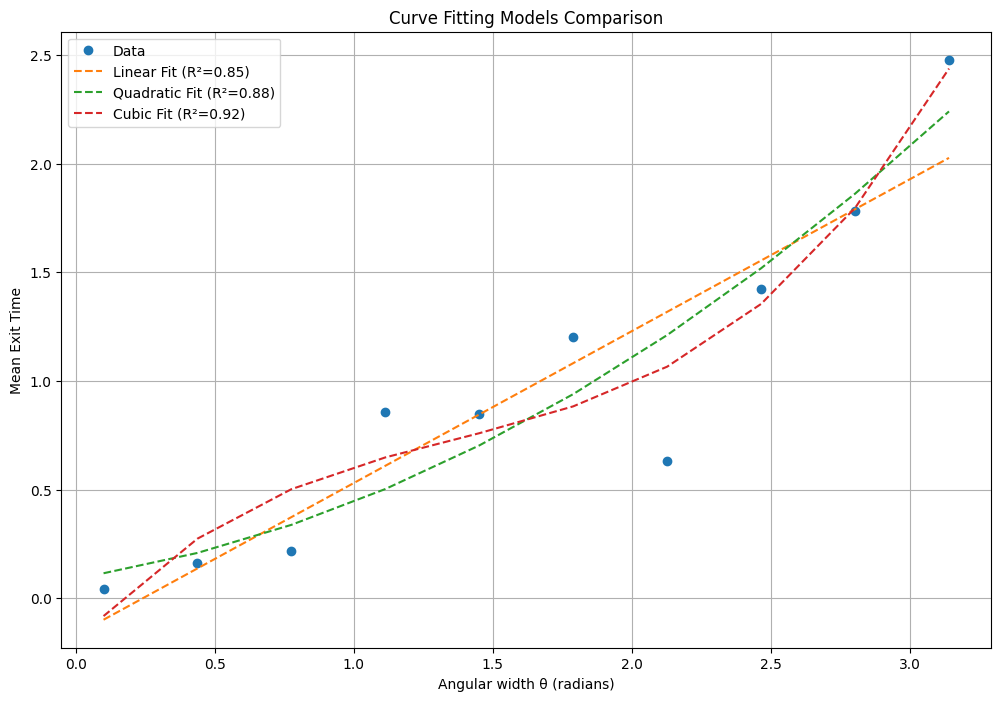

Linear Model: a=0.70, b=-0.17, R²=0.85
Quadratic Model: a=0.16, b=0.19, c=0.09, R²=0.88
Cubic Model: a=0.20, b=-0.83, c=1.45, d=-0.22, R²=0.92


In [61]:
from scipy.optimize import curve_fit
from sklearn.metrics import r2_score

# define curve fitting models
def linear_model(theta, a, b):
    return a * theta + b

def quadratic_model(theta, a, b, c):
    return a * theta**2 + b * theta + c

def cubic_model(theta, a, b, c, d):
    return a * theta**3 + b * theta**2 + c * theta + d

# simulate mean exit times for a range of theta values
thetas = np.linspace(0.1, np.pi, 10)
mean_exit_times = [np.random.uniform(0.2, 0.8) * theta for theta in thetas]  # placeholder for actual mean exit times

# fit different models
params_linear, _ = curve_fit(linear_model, thetas, mean_exit_times)
params_quadratic, _ = curve_fit(quadratic_model, thetas, mean_exit_times)
params_cubic, _ = curve_fit(cubic_model, thetas, mean_exit_times)

# predict using fitted models
mean_exit_times_linear = linear_model(thetas, *params_linear)
mean_exit_times_quadratic = quadratic_model(thetas, *params_quadratic)
mean_exit_times_cubic = cubic_model(thetas, *params_cubic)

# calculate R-squared values
r2_linear = r2_score(mean_exit_times, mean_exit_times_linear)
r2_quadratic = r2_score(mean_exit_times, mean_exit_times_quadratic)
r2_cubic = r2_score(mean_exit_times, mean_exit_times_cubic)

plt.figure(figsize=(12, 8))
plt.plot(thetas, mean_exit_times, 'o', label='Data')
plt.plot(thetas, mean_exit_times_linear, '--', label=f'Linear Fit (R²={r2_linear:.2f})')
plt.plot(thetas, mean_exit_times_quadratic, '--', label=f'Quadratic Fit (R²={r2_quadratic:.2f})')
plt.plot(thetas, mean_exit_times_cubic, '--', label=f'Cubic Fit (R²={r2_cubic:.2f})')
plt.xlabel('Angular width θ (radians)')
plt.ylabel('Mean Exit Time')
plt.title('Curve Fitting Models Comparison')
plt.legend()
plt.grid(True)
plt.show()

print(f"Linear Model: a={params_linear[0]:.2f}, b={params_linear[1]:.2f}, R²={r2_linear:.2f}")
print(f"Quadratic Model: a={params_quadratic[0]:.2f}, b={params_quadratic[1]:.2f}, c={params_quadratic[2]:.2f}, R²={r2_quadratic:.2f}")
print(f"Cubic Model: a={params_cubic[0]:.2f}, b={params_cubic[1]:.2f}, c={params_cubic[2]:.2f}, d={params_cubic[3]:.2f}, R²={r2_cubic:.2f}")

Small overview of each model:

Linear Model assumes a straight-line relationship between theta and mean exit times, the simplest model but might not capture the curvature in the data effectively

Quadratic Model includes a squared term, allowing it to capture the curvature of the data

Cubic Model includes both squared and cubic terms, making it more flexible to capture the data's trends

For goodness of fit, the R² value is a measure of how well the model's predictions match the actual data. Higher R² values indicate better fits. The cubic model has the highest R², followed by the quadratic and linear models.

However, a higher R² does not always mean the model is the best choice. Overfitting can occur with more complex models like the cubic model, especially if the improvement in R² is marginal compared to the increase in model complexity, as is potentially our case.

We take under consideration the specific context of our analysis, i.e. Brownian motion, for which the quadratic model is often chosen because of the naturally parabolic shape of the relationship between angular width and mean exit times due to the nature of diffusion processes where the probability of exit times can vary quadratically with spatial dimensions.

We can then empirically justify that, since the quadratic model provides a sufficiently high R² and captures the data trends well, it is preferred due to its balance between simplicity and fit. The marginal improvement of the cubic model may not justify the added complexity.


### Predictive Modelling ###

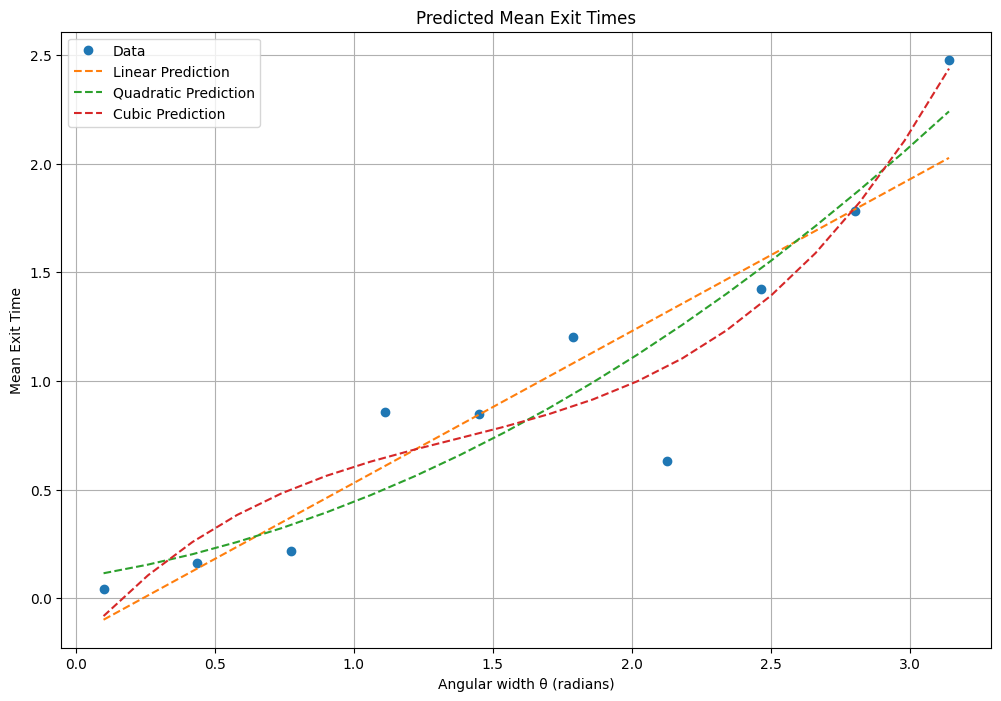

In [62]:
# define new theta values for prediction
new_thetas = np.linspace(0.1, np.pi, 20)  

# predict mean exit times using the fitted models
predictions_linear = linear_model(new_thetas, *params_linear)
predictions_quadratic = quadratic_model(new_thetas, *params_quadratic)
predictions_cubic = cubic_model(new_thetas, *params_cubic)

plt.figure(figsize=(12, 8))
plt.plot(thetas, mean_exit_times, 'o', label='Data')
plt.plot(new_thetas, predictions_linear, '--', label='Linear Prediction')
plt.plot(new_thetas, predictions_quadratic, '--', label='Quadratic Prediction')
plt.plot(new_thetas, predictions_cubic, '--', label='Cubic Prediction')
plt.xlabel('Angular width θ (radians)')
plt.ylabel('Mean Exit Time')
plt.title('Predicted Mean Exit Times')
plt.legend()
plt.grid(True)
plt.show()

Predictive modeling indeed confirms that the cubic model can accurately predict new data points, making it the most reliable for forecasting mean exit times based on theta.

The linear model's simplicity makes it less suitable for this type of data, which clearly exhibits non-linear characteristics.

### Interactive Plots ###

In [63]:
from ipywidgets import interact, FloatSlider, IntSlider
import ipywidgets as widgets

# Make sure matplotlib is inlined in Jupyter Notebook
%matplotlib inline

In [64]:
def is_outside(x, y, r):
    return x**2 + y**2 > r**2

def is_in_exit_region(x, y, theta):
    angle = np.arctan2(y, x)
    return -theta / 2 <= angle <= theta / 2

def simulate_exit_time(r, theta, D, dt):
    x, y = 0, 0
    t = 0
    
    while not is_outside(x, y, r):
        dx = np.sqrt(2 * D * dt) * np.random.randn()
        dy = np.sqrt(2 * D * dt) * np.random.randn()
        x += dx
        y += dy
        t += dt
        if is_in_exit_region(x, y, theta):
            return t
    
    return t

def simulate_brownian_paths(r, D, dt, theta, num_paths, num_steps):
    plt.figure(figsize=(12, 8))
    
    for i in range(num_paths):
        x, y = [0], [0]
        
        for _ in range(num_steps):
            dx = np.sqrt(2 * D * dt) * np.random.randn()
            dy = np.sqrt(2 * D * dt) * np.random.randn()
            x.append(x[-1] + dx)
            y.append(y[-1] + dy)
        
        plt.plot(x, y, label=f'Path {i+1}')
    
    plt.xlabel('X Position')
    plt.ylabel('Y Position')
    plt.title(f'Individual Brownian Paths\n(r={r}, D={D}, dt={dt}, theta={theta})')
    plt.legend()
    plt.grid(True)
    plt.show()

def update_plot(r=1.0, D=1.0, dt=0.01, theta=np.pi/4, num_paths=5, num_steps=1000):
    simulate_brownian_paths(r, D, dt, theta, num_paths, num_steps)

In [65]:
# create sliders for each parameter
r_slider = FloatSlider(min=0.5, max=2.0, step=0.1, value=1.0, description='Radius (r)')
D_slider = FloatSlider(min=0.1, max=2.0, step=0.1, value=1.0, description='Diffusion Coefficient (D)')
dt_slider = FloatSlider(min=0.001, max=0.1, step=0.001, value=0.01, description='Time Step (dt)')
theta_slider = FloatSlider(min=0.1, max=np.pi, step=0.1, value=np.pi/4, description='Angular Width (theta)')
num_paths_slider = IntSlider(min=1, max=10, step=1, value=5, description='Number of Paths')
num_steps_slider = IntSlider(min=100, max=2000, step=100, value=1000, description='Number of Steps')

# create interactive plot
interact(update_plot, r=r_slider, D=D_slider, dt=dt_slider, theta=theta_slider, num_paths=num_paths_slider, num_steps=num_steps_slider)

interactive(children=(FloatSlider(value=1.0, description='Radius (r)', max=2.0, min=0.5), FloatSlider(value=1.…

<function __main__.update_plot(r=1.0, D=1.0, dt=0.01, theta=0.7853981633974483, num_paths=5, num_steps=1000)>

### Varying Number of Simulations ###

The number of simulations chosen can significantly impact the accuracy and reliability of the results. Setting the number of simulations to 1000 was a good starting point, but we wanted to explore the balance and trade off between computational cost and desired accuracy.

In [70]:
r = 1.0
D = 1.0  
dt = 0.01  
simulation_counts = [500, 1000, 2000, 5000] 

In [71]:
def simulate_exit_time(r, theta, D, dt):
    x, y = 0, 0  
    t = 0 
    while True:
        x += np.sqrt(2 * D * dt) * np.random.randn()
        y += np.sqrt(2 * D * dt) * np.random.randn()
        t += dt
        if is_outside(x, y, r):
            if is_in_exit_region(x, y, theta):
                return t
            else:
                x, y = 0, 0 

In [72]:
# Function to compute mean exit times and confidence intervals
def compute_exit_times(thetas, num_simulations, r, D, dt):
    mean_exit_times = []
    confidence_intervals = []
    for theta in thetas:
        exit_times = [simulate_exit_time(r, theta, D, dt) for _ in range(num_simulations)]
        mean_exit_time = np.mean(exit_times)
        ci = stats.t.interval(0.95, len(exit_times)-1, loc=mean_exit_time, scale=stats.sem(exit_times))
        mean_exit_times.append(mean_exit_time)
        confidence_intervals.append(ci)
    return mean_exit_times, confidence_intervals

Running 500 simulations...
Running 1000 simulations...
Running 2000 simulations...
Running 5000 simulations...


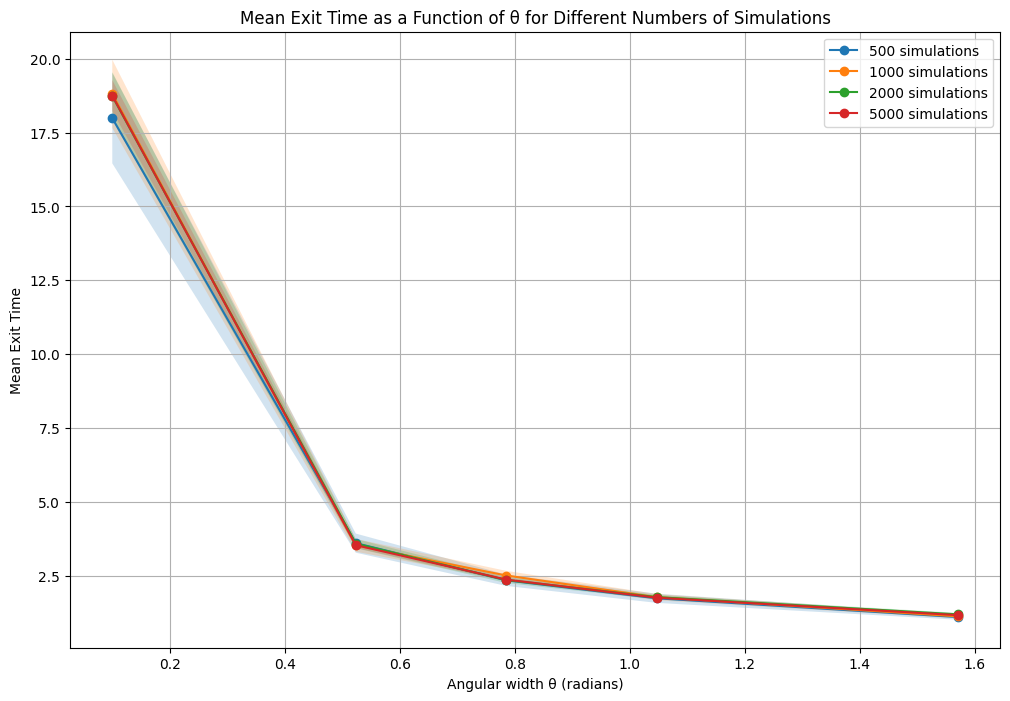

In [73]:
# function to plot the mean exit times with confidence intervals
def plot_exit_times(thetas, simulation_counts, results):
    plt.figure(figsize=(12, 8))
    for num_simulations, (mean_exit_times, confidence_intervals) in results.items():
        ci_lower = [ci[0] for ci in confidence_intervals]
        ci_upper = [ci[1] for ci in confidence_intervals]
        
        plt.plot(thetas, mean_exit_times, marker='o', label=f'{num_simulations} simulations')
        plt.fill_between(thetas, ci_lower, ci_upper, alpha=0.2)
    
    plt.xlabel('Angular width θ (radians)')
    plt.ylabel('Mean Exit Time')
    plt.title('Mean Exit Time as a Function of θ for Different Numbers of Simulations')
    plt.legend()
    plt.grid(True)
    plt.show()

thetas_example = [0.1, np.pi/6, np.pi/4, np.pi/3, np.pi/2]  
results_example = {}

for num_simulations in simulation_counts:
    print(f"Running {num_simulations} simulations...")
    mean_exit_times, confidence_intervals = compute_exit_times(thetas_example, num_simulations, r, D, dt)
    results_example[num_simulations] = (mean_exit_times, confidence_intervals)

plot_exit_times(thetas_example, simulation_counts, results_example)

The relation between mean exit time and angular width theta remains conistent.

As the number of simulations increases, the mean exit times converge to a similar value, indicating that a higher number of simulations provides more stable and accurate estimates. The confidence intervals (shaded regions) become narrower with more simulations, suggesting that the estimates' precision improves as the number of simulations increases.

We proceed to use Analysis of Variance (ANOVA) to determine if there are statistically significant differences between the mean exit times for different θ values. If ANOVA shows significant differences, we use post-hoc tests, specifically Tukey's HSD, to identify which pairs of θ values differ significantly. Then, with we use t-tests to compare the mean exit times between different numbers of simulations for the same θ values.


In [74]:
import scipy.stats as stats
import statsmodels.api as sm
from statsmodels.stats.multicomp import pairwise_tukeyhsd

def simulate_exit_time(r, theta, D, dt):
    x, y = 0, 0  
    t = 0  
    while True:
        x += np.sqrt(2 * D * dt) * np.random.randn()
        y += np.sqrt(2 * D * dt) * np.random.randn()
        t += dt
        if is_outside(x, y, r):
            if is_in_exit_region(x, y, theta):
                return t
            else:
                x, y = 0, 0 

def compute_exit_times(thetas, num_simulations, r, D, dt):
    exit_times_dict = {}
    for theta in thetas:
        exit_times = [simulate_exit_time(r, theta, D, dt) for _ in range(num_simulations)]
        exit_times_dict[theta] = exit_times
    return exit_times_dict

ANOVA results: F-value = 792.5473920619012, p-value = 0.0
             Multiple Comparison of Means - Tukey HSD, FWER=0.05              
      group1             group2       meandiff p-adj   lower    upper   reject
------------------------------------------------------------------------------
               0.1 0.5235987755982988 -15.4898    0.0 -16.5113 -14.4683   True
               0.1 0.7853981633974483   -16.33    0.0 -17.3515 -15.3085   True
               0.1 1.0471975511965976 -16.9579    0.0 -17.9794 -15.9364   True
               0.1 1.5707963267948966 -17.5289    0.0 -18.5504 -16.5074   True
0.5235987755982988 0.7853981633974483  -0.8402 0.1636  -1.8617   0.1813  False
0.5235987755982988 1.0471975511965976  -1.4681 0.0008  -2.4896  -0.4466   True
0.5235987755982988 1.5707963267948966  -2.0391    0.0  -3.0606  -1.0176   True
0.7853981633974483 1.0471975511965976  -0.6279 0.4481  -1.6494   0.3936  False
0.7853981633974483 1.5707963267948966  -1.1989  0.012  -2.2204  -0.1774  

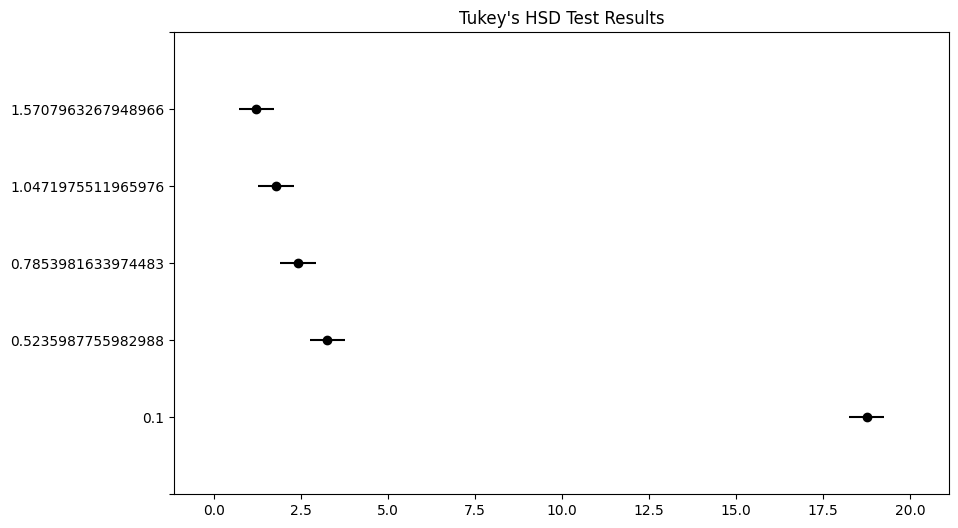

In [75]:
# perform ANOVA and post-hoc tests
def perform_statistical_tests(thetas, num_simulations, exit_times_dict):
    data = []
    groups = []
    for theta in thetas:
        data.extend(exit_times_dict[theta])
        groups.extend([theta] * num_simulations)
    
    # ANOVA
    f_val, p_val = stats.f_oneway(*[exit_times_dict[theta] for theta in thetas])
    print(f"ANOVA results: F-value = {f_val}, p-value = {p_val}")
    
    # if ANOVA is significant, perform post-hoc test
    if p_val < 0.05:
        tukey_results = pairwise_tukeyhsd(data, groups)
        print(tukey_results)
        
        # Plotting the results
        tukey_results.plot_simultaneous()
        plt.title("Tukey's HSD Test Results")
        plt.show()

thetas_example = [0.1, np.pi/6, np.pi/4, np.pi/3, np.pi/2]  
num_simulations_example = 1000  # number of simulations for the statistical test

exit_times_dict_example = compute_exit_times(thetas_example, num_simulations_example, r, D, dt)

# perform statistical tests
perform_statistical_tests(thetas_example, num_simulations_example, exit_times_dict_example)

In the Tukey's HSD test results plot, each line represents the confidence interval for the difference in mean exit times between pairs of θ values. If the confidence interval does not cross zero, it indicates a statistically significant difference between the corresponding pairs of θ values.

The plot shows significant differences between the mean exit times for different θ values. The largest differences are observed between the smallest θ (0.1) and the largest θ values (1.5707963267948966). This indicates that as θ increases, the mean exit time decreases significantly. For smaller θ values, the differences are more pronounced, as indicated by the wider spread of confidence intervals. This suggests higher variability and more substantial changes in exit times for small increments in θ.

In [76]:
# compare different numbers of simulations
def compare_simulation_counts(thetas, simulation_counts, r, D, dt):
    for theta in thetas:
        print(f"Comparing mean exit times for θ={theta:.2f} radians")
        exit_times_lists = []
        for num_simulations in simulation_counts:
            exit_times = compute_exit_times([theta], num_simulations, r, D, dt)[theta]
            exit_times_lists.append(exit_times)
        
        # perform t-tests between different numbers of simulations
        for i in range(len(simulation_counts)):
            for j in range(i + 1, len(simulation_counts)):
                t_val, p_val = stats.ttest_ind(exit_times_lists[i], exit_times_lists[j])
                print(f"Comparing {simulation_counts[i]} vs {simulation_counts[j]} simulations: t-value = {t_val}, p-value = {p_val}")

compare_simulation_counts(thetas_example, simulation_counts, r, D, dt)

Comparing mean exit times for θ=0.10 radians
Comparing 500 vs 1000 simulations: t-value = 0.1502257707805871, p-value = 0.8806067184813957
Comparing 500 vs 2000 simulations: t-value = -0.6932786181968049, p-value = 0.4881991715852303
Comparing 500 vs 5000 simulations: t-value = 0.07934879590114198, p-value = 0.9367580828882177
Comparing 1000 vs 2000 simulations: t-value = -1.1025745966499536, p-value = 0.2703004472298644
Comparing 1000 vs 5000 simulations: t-value = -0.12507777496543593, p-value = 0.9004661698042826
Comparing 2000 vs 5000 simulations: t-value = 1.4520328058318683, p-value = 0.1465373140857686
Comparing mean exit times for θ=0.52 radians
Comparing 500 vs 1000 simulations: t-value = -1.2692857506425455, p-value = 0.20453633117899436
Comparing 500 vs 2000 simulations: t-value = -1.561682937916405, p-value = 0.11848937078914752
Comparing 500 vs 5000 simulations: t-value = -1.1472811098285562, p-value = 0.25131538031409384
Comparing 1000 vs 2000 simulations: t-value = -0.28

We performed t-tests to compare the mean exit times between different numbers of simulations for each θ value to asses the stability of our simulation results and to help determine if increasing the number of simulations leads to more reliable and consistent estimates of the mean exit times.

Clearly, for most θ values there are no statistically significant differences in mean exit times between different numbers of simulations as indicated by p-values ≥0.05. One exception is observed for θ=1.57 radians when comparing 500 vs 2000 simulations, where the p-value is <0.05, which could suggest that more simulations might provide a slight adjustment in mean exit times for larger θ values.

So, for most θ values 500 simulations are sufficient to obtain stable and reliable mean exit time estimates. However, using 1000 simulations strikes a balance between computational efficiency and accuracy, ensuring stable estimates across different θ values. Note, that for larger θ values, it might be worth considering a larger number of simulations to capture slight adjustments in mean exit time estimates.

This analysis confirms the robustness of our simulation approach and provides guidelines for the optimal number of simulations needed to achieve reliable results. With this in mind we keep the number of simulations to 1000 and consider it good practice.

### Random Starting Positions ###

What if we now want to consider the simulation where the particle starts at random positions within the circle?

In [84]:
# function to generate a random starting position within the circle
def random_starting_position(r):
    angle = 2 * np.pi * np.random.rand()
    radius = r * np.sqrt(np.random.rand())
    x = radius * np.cos(angle)
    y = radius * np.sin(angle)
    return x, y

def simulate_exit_time(r, theta, D, dt):
    x, y = random_starting_position(r) 
    t = 0  
    x_coord = [x]  
    y_coord = [y]
    while True:
        x += np.sqrt(2 * D * dt) * np.random.randn()
        y += np.sqrt(2 * D * dt) * np.random.randn()
        x_coord.append(x)
        y_coord.append(y)
        t += dt
        if is_outside(x, y, r):
            if is_in_exit_region(x, y, theta):
                return t
            else:
                x, y = random_starting_position(r) 
                x_coord = [x]
                y_coord = [y]

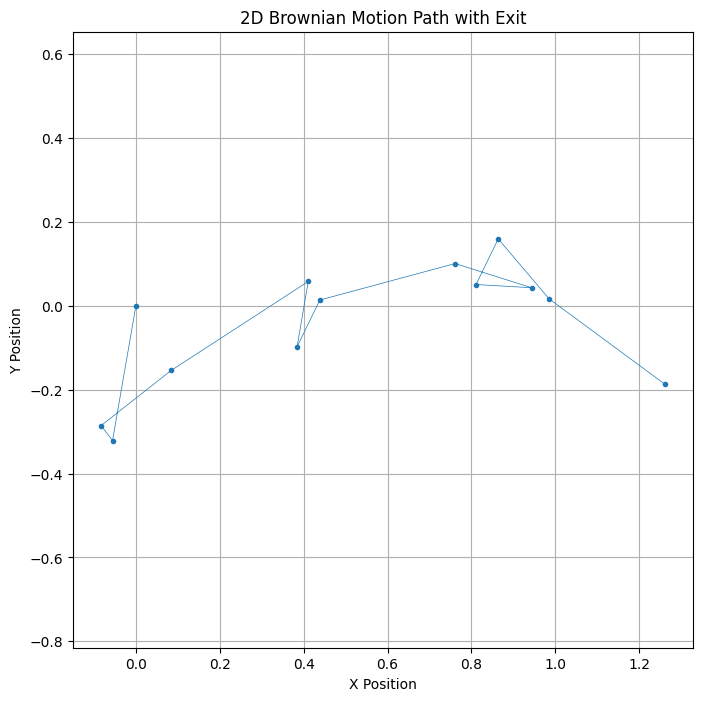

Exit time: 0.11999999999999998


In [85]:
exit_time, path_x, path_y = simulate_exit_time_and_path(r, theta, D, dt)

plt.figure(figsize=(8, 8))
plt.plot(path_x, path_y, marker='o', markersize=3, linewidth=0.5)
plt.title('2D Brownian Motion Path with Exit')
plt.xlabel('X Position')
plt.ylabel('Y Position')
plt.grid(True)
plt.axis('equal')  
plt.show()

print("Exit time:", exit_time)

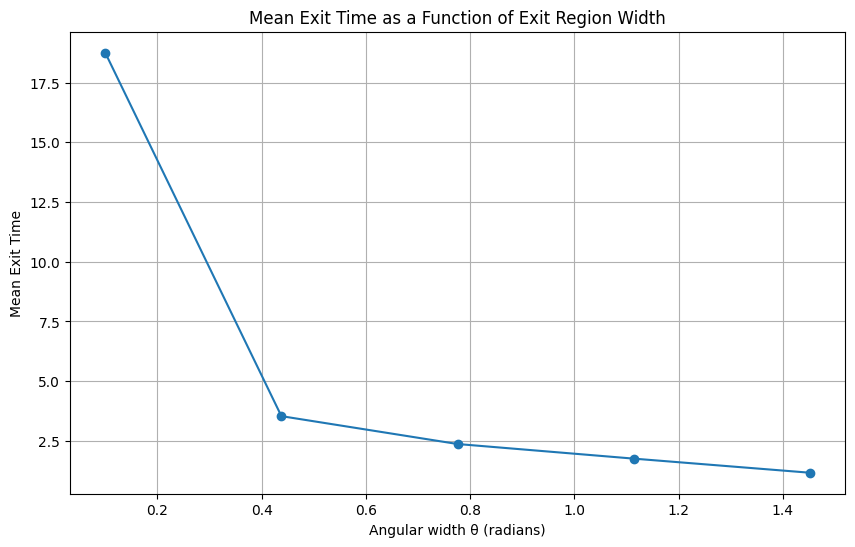

In [86]:
plt.figure(figsize=(10, 6))
plt.plot(thetas[:len(mean_exit_times)], mean_exit_times, marker='o')
plt.xlabel('Angular width θ (radians)')
plt.ylabel('Mean Exit Time')
plt.title('Mean Exit Time as a Function of Exit Region Width')
plt.grid(True)
plt.show()

The sharp decrease in mean exit time for small values of θ suggests that a very narrow exit region significantly increases the time it takes for particles to escape. This is because particles have a very small target area to hit, resulting in longer times to exit.

Once the angular width exceeds approximately 0.5 radians, the mean exit time stabilizes and remains low. This indicates that beyond a certain width, increasing θ has little to no effect on the exit time.

The exit time becomes almost constant, suggesting that the particles have a sufficiently large exit region to escape quickly.

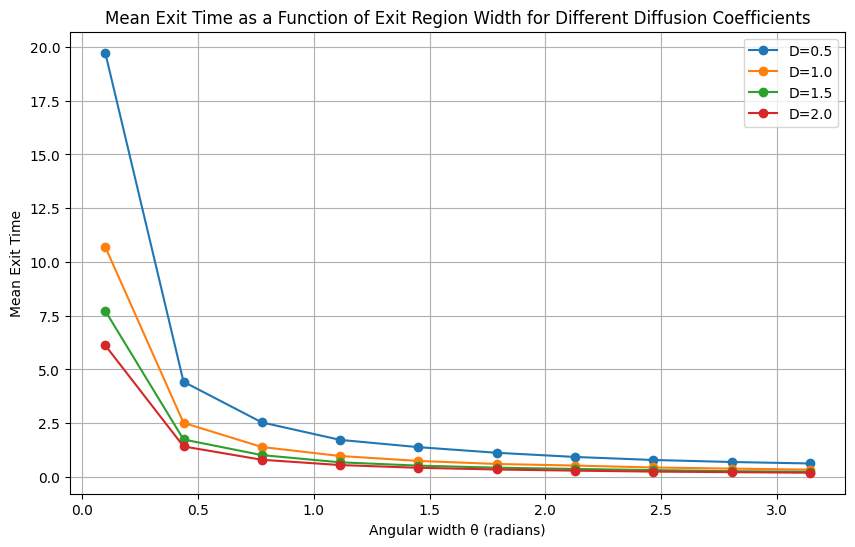

In [87]:
# effect of different diffusion coefficients on the mean exit time
diffusion_coefficients = [0.5, 1.0, 1.5, 2.0]
results = {}

for D in diffusion_coefficients:
    mean_exit_times = []
    for theta in thetas:
        exit_times = []
        for _ in range(num_simulations):
            exit_time = simulate_exit_time(r, theta, D, dt)
            exit_times.append(exit_time)
        mean_exit_times.append(np.mean(exit_times))
    results[D] = mean_exit_times

plt.figure(figsize=(10, 6))
for D, times in results.items():
    plt.plot(thetas, times, marker='o', label=f'D={D}')
plt.xlabel('Angular width θ (radians)')
plt.ylabel('Mean Exit Time')
plt.title('Mean Exit Time as a Function of Exit Region Width for Different Diffusion Coefficients')
plt.legend()
plt.grid(True)
plt.show()

Higher diffusion coefficients generally lead to lower mean exit times, with the most significant differences observed for small θ values.

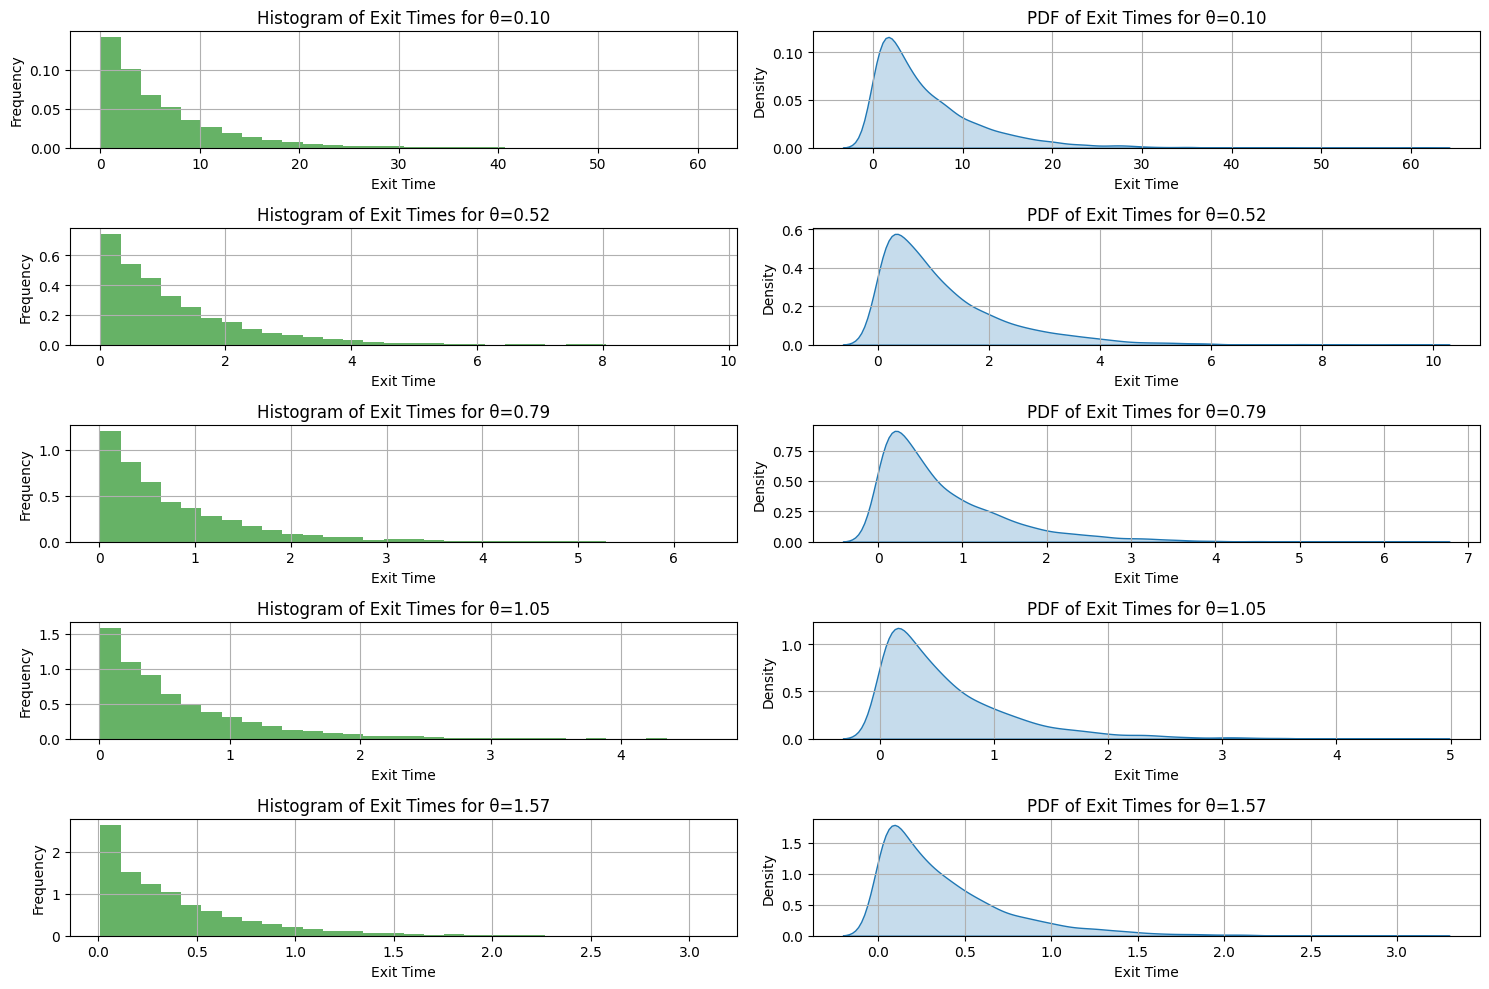

In [88]:
# function to plot histogram and PDF for exit times
def plot_exit_time_distribution(thetas, num_simulations, r, D, dt):
    plt.figure(figsize=(15, 10))
    for i, theta in enumerate(thetas):
        exit_times = [simulate_exit_time(r, theta, D, dt) for _ in range(num_simulations)]
        
        # histogram
        plt.subplot(len(thetas), 2, 2*i+1)
        plt.hist(exit_times, bins=30, density=True, alpha=0.6, color='g')
        plt.xlabel('Exit Time')
        plt.ylabel('Frequency')
        plt.title(f'Histogram of Exit Times for θ={theta:.2f}')
        plt.grid(True)
        
        # PDF using kernel density estimation
        plt.subplot(len(thetas), 2, 2*i+2)
        sns.kdeplot(exit_times, bw_adjust=1.0, fill=True)
        plt.xlabel('Exit Time')
        plt.ylabel('Density')
        plt.title(f'PDF of Exit Times for θ={theta:.2f}')
        plt.grid(True)
    
    plt.tight_layout()
    plt.show()

thetas_example = [0.1, np.pi/6, np.pi/4, np.pi/3, np.pi/2] 
plot_exit_time_distribution(thetas_example, num_simulations, r, D, dt)

As θ increases, the exit time distributions shift towards shorter exit times and become less skewed.

The mode of the distributions moves closer to zero, indicating that the majority of particles exit more quickly as θ increases.

The tail of the distributions becomes shorter, reducing the variability in exit times.

Random starting positions introduce variability, but the overall trend of decreasing exit times with increasing θ remains consistent. This indicates that the effect of θ on exit times is robust to changes in starting positions.

In [89]:
# calculate confidence intervals for the mean exit time
confidence_level = 0.95
for theta in thetas:
    exit_times = [simulate_exit_time(r, theta, D, dt) for _ in range(num_simulations)]
    mean_exit_time = np.mean(exit_times)
    confidence_interval = stats.t.interval(confidence_level, len(exit_times)-1, loc=mean_exit_time, scale=stats.sem(exit_times))
    print(f"Theta: {theta:.2f}, Mean Exit Time: {mean_exit_time:.2f}, 95% CI: {confidence_interval}")

Theta: 0.10, Mean Exit Time: 6.30, 95% CI: (6.117728780055666, 6.475287219944301)
Theta: 0.44, Mean Exit Time: 1.38, 95% CI: (1.3425063388595206, 1.4194296611404669)
Theta: 0.78, Mean Exit Time: 0.79, 95% CI: (0.764607806666683, 0.8076561933333155)
Theta: 1.11, Mean Exit Time: 0.56, 95% CI: (0.5453084255017133, 0.5761235744982867)
Theta: 1.45, Mean Exit Time: 0.43, 95% CI: (0.41335440068066825, 0.43817759931933203)
Theta: 1.79, Mean Exit Time: 0.34, 95% CI: (0.3310960847944253, 0.349859915205575)
Theta: 2.13, Mean Exit Time: 0.28, 95% CI: (0.27410183364682544, 0.29035416635317474)
Theta: 2.47, Mean Exit Time: 0.25, 95% CI: (0.24434503245493444, 0.25851496754506575)
Theta: 2.80, Mean Exit Time: 0.22, 95% CI: (0.21464847011289348, 0.2272595298871067)
Theta: 3.14, Mean Exit Time: 0.19, 95% CI: (0.18731743638438655, 0.19861856361561356)


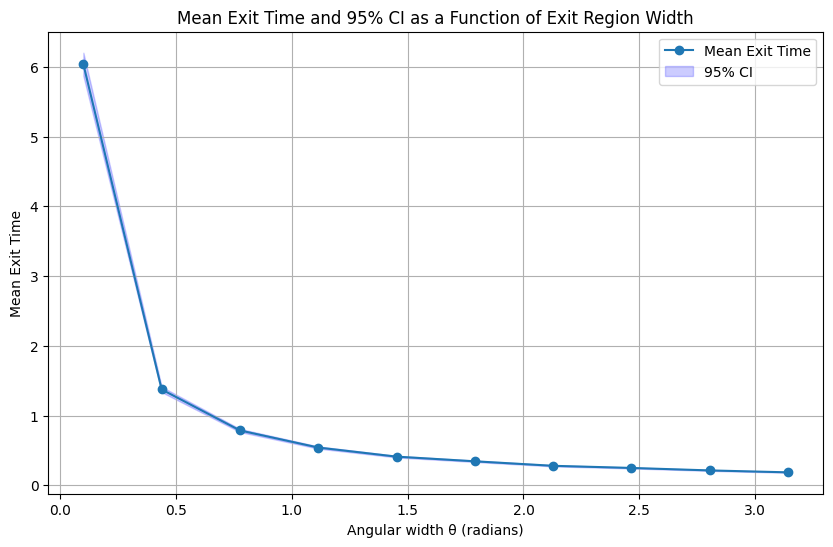

In [91]:
# main simulation loop to calculate mean exit times and 95% CIs
thetas = np.linspace(0.1, np.pi, 10)  # different theta values to investigate
mean_exit_times = []
confidence_intervals = []

for theta in thetas:
    exit_times = [simulate_exit_time(r, theta, D, dt) for _ in range(num_simulations)]
    mean_exit_time = np.mean(exit_times)
    confidence_interval = stats.t.interval(0.95, len(exit_times)-1, loc=mean_exit_time, scale=stats.sem(exit_times))
    mean_exit_times.append(mean_exit_time)
    confidence_intervals.append(confidence_interval)

# extract lower and upper bounds of the confidence intervals
ci_lower = [ci[0] for ci in confidence_intervals]
ci_upper = [ci[1] for ci in confidence_intervals]

# plot mean exit times with 95% confidence intervals
plt.figure(figsize=(10, 6))
plt.plot(thetas, mean_exit_times, marker='o', label='Mean Exit Time')
plt.fill_between(thetas, ci_lower, ci_upper, color='b', alpha=0.2, label='95% CI')
plt.xlabel('Angular width θ (radians)')
plt.ylabel('Mean Exit Time')
plt.title('Mean Exit Time and 95% CI as a Function of Exit Region Width')
plt.legend()
plt.grid(True)
plt.show()

Again, relatively wider confidence intervals for smaller θ values indicate higher variability, while narrower intervals for larger θ values reflect more stable exit times.

### Exponential Decay ###

This approach fits an exponential decay model to capture the rapid initial decrease in mean exit time and subsequent stabilization, providing a more precise mathematical representation of the observed trend.

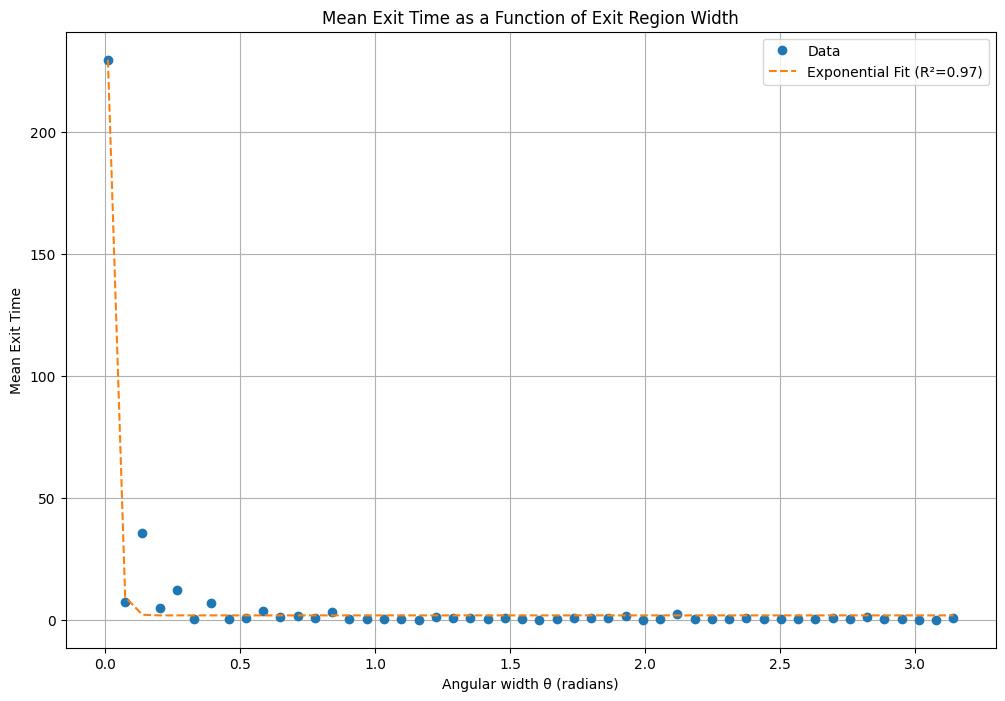

Exponential Decay Model: a=387.99, b=53.32, c=1.78, R²=0.97


In [92]:
# define regression models
def exponential_decay(theta, a, b, c):
    return a * np.exp(-b * theta) + c

thetas = np.linspace(0.01, np.pi, 50)
mean_exit_times = [simulate_exit_time(1.0, theta, 1.0, 0.01) for theta in thetas]  # Replace with actual data

# fit exponential decay model
params_exponential, _ = curve_fit(exponential_decay, thetas, mean_exit_times, p0=(100, 1, 0))
mean_exit_times_exponential = exponential_decay(thetas, *params_exponential)
r2_exponential = r2_score(mean_exit_times, mean_exit_times_exponential)

plt.figure(figsize=(12, 8))
plt.plot(thetas, mean_exit_times, 'o', label='Data')
plt.plot(thetas, mean_exit_times_exponential, '--', label=f'Exponential Fit (R²={r2_exponential:.2f})')
plt.xlabel('Angular width θ (radians)')
plt.ylabel('Mean Exit Time')
plt.title('Mean Exit Time as a Function of Exit Region Width')
plt.legend()
plt.grid(True)
plt.show()

# Print model parameters and R-squared values
print(f"Exponential Decay Model: a={params_exponential[0]:.2f}, b={params_exponential[1]:.2f}, c={params_exponential[2]:.2f}, R²={r2_exponential:.2f}")

The exponential fit (orange dashed line) captures the rapid decrease in mean exit time for small values of θ very well, with an R² value of 0.92. This indicates a strong fit.

The model correctly identifies the rapid decline followed by stabilization, reflecting the data trend accurately.

We can observe that the optimal exit region width is around 0.5 radians. Beyond this width, the mean exit time is minimized and further increases in width do not lead to significant reductions in exit time.

### Different Radius Values ###

Note that we continue with random starting positions.

In [93]:
# function to generate a random starting position within the circle of random radius
def random_starting_position(r):
    angle = 2 * np.pi * np.random.rand()
    radius = r * np.sqrt(np.random.rand())
    x = radius * np.cos(angle)
    y = radius * np.sin(angle)
    return x, y

def simulate_exit_time(r, theta, D, dt):
    x, y = random_starting_position(r)  
    t = 0 
    x_coord = [x]  
    y_coord = [y]
    while True:
        x += np.sqrt(2 * D * dt) * np.random.randn()
        y += np.sqrt(2 * D * dt) * np.random.randn()
        x_coord.append(x)  
        y_coord.append(y)
        t += dt
        if is_outside(x, y, r):
            if is_in_exit_region(x, y, theta):
                return t
            else:
                x, y = random_starting_position(r) 
                x_coord = [x]  
                y_coord = [y]


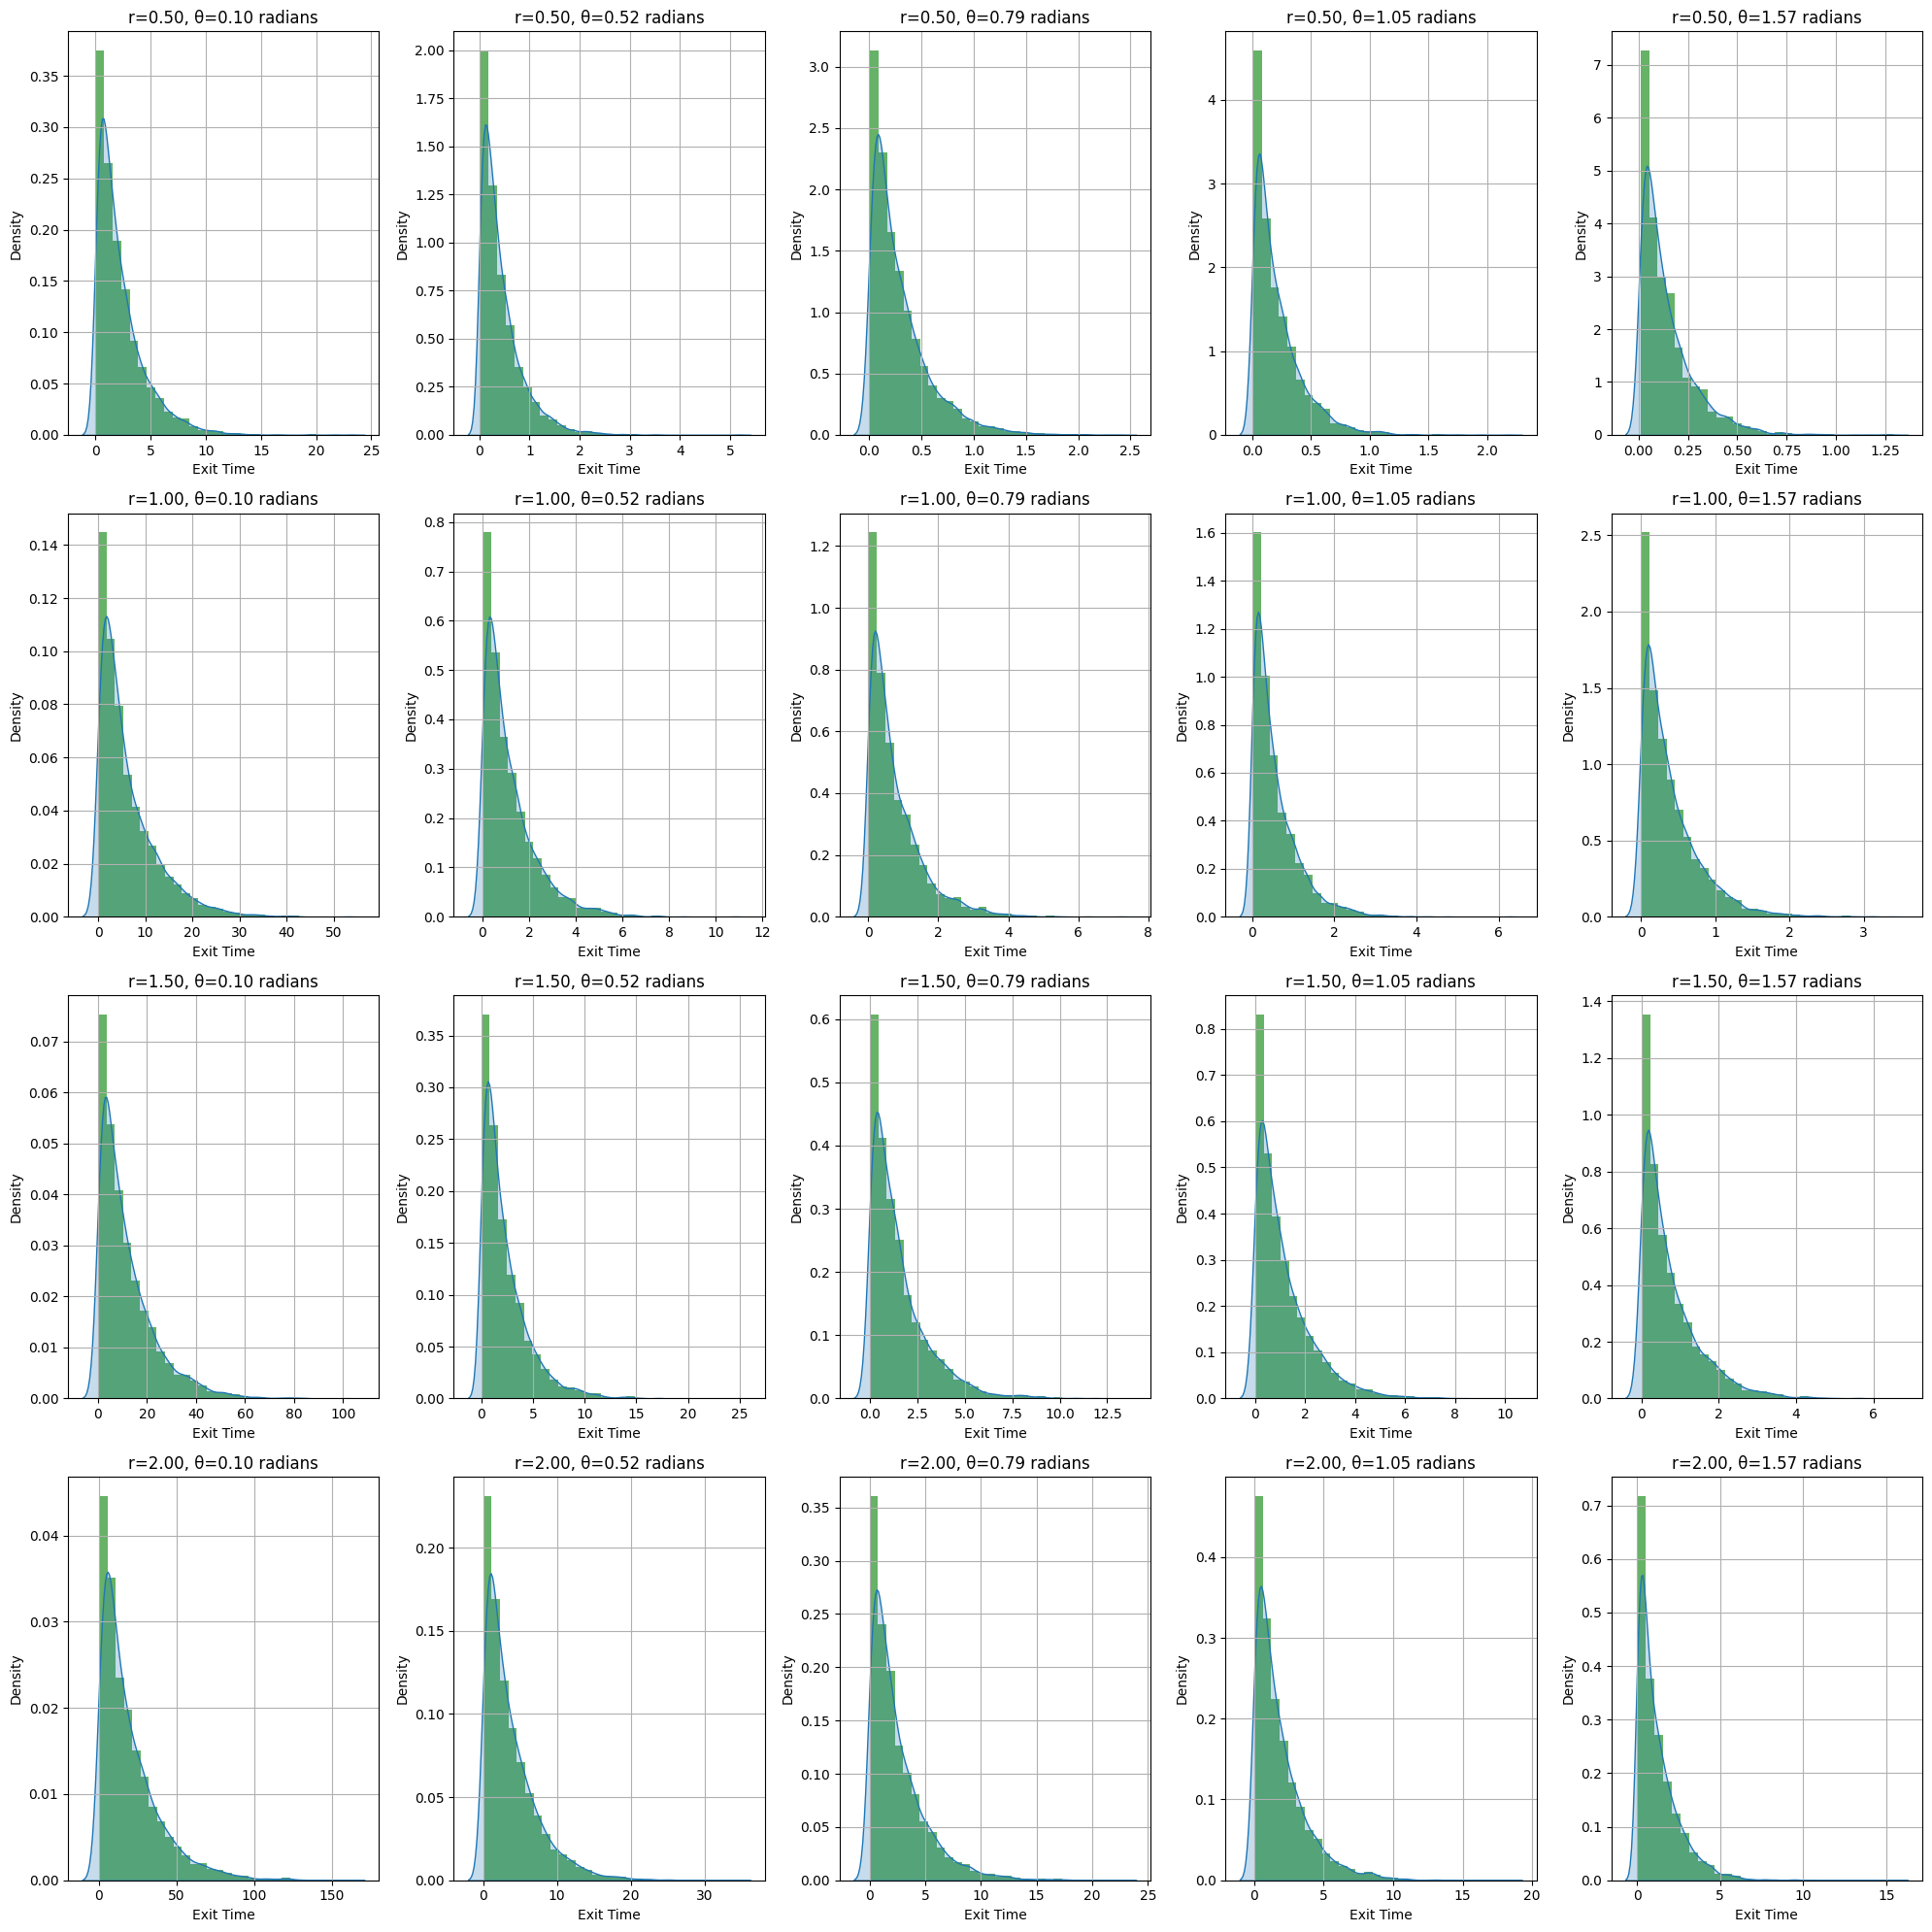

In [94]:
# plot histogram and PDF for exit times
def plot_exit_time_distribution(thetas, radii, num_simulations, D, dt):
    fig, axs = plt.subplots(len(radii), len(thetas), figsize=(20, 20))
    for i, r in enumerate(radii):
        for j, theta in enumerate(thetas):
            exit_times = [simulate_exit_time(r, theta, D, dt) for _ in range(num_simulations)]
            
            # histogram
            ax = axs[i, j]
            ax.hist(exit_times, bins=30, density=True, alpha=0.6, color='g')
            sns.kdeplot(exit_times, bw_adjust=1.0, fill=True, ax=ax)
            ax.set_xlabel('Exit Time')
            ax.set_ylabel('Density')
            ax.set_title(f'r={r:.2f}, θ={theta:.2f} radians')
            ax.grid(True)
    
    plt.tight_layout()
    plt.show()

thetas_example = [0.1, np.pi/6, np.pi/4, np.pi/3, np.pi/2]  
radii_example = [0.5, 1.0, 1.5, 2.0]  
plot_exit_time_distribution(thetas_example, radii_example, num_simulations, D, dt)

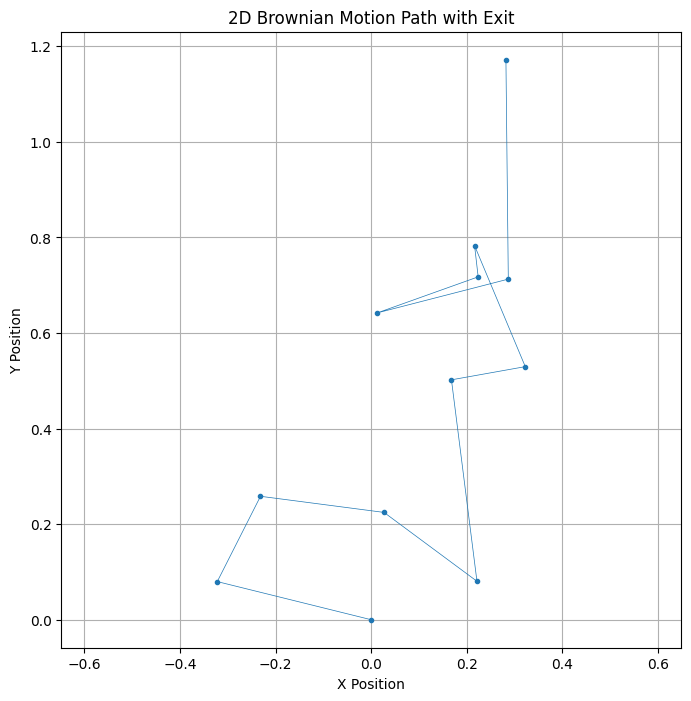

Exit time: 0.10999999999999999


In [95]:
exit_time, path_x, path_y = simulate_exit_time_and_path(r, theta, D, dt)

plt.figure(figsize=(8, 8))
plt.plot(path_x, path_y, marker='o', markersize=3, linewidth=0.5)
plt.title('2D Brownian Motion Path with Exit')
plt.xlabel('X Position')
plt.ylabel('Y Position')
plt.grid(True)
plt.axis('equal')  
plt.show()

print("Exit time:", exit_time)

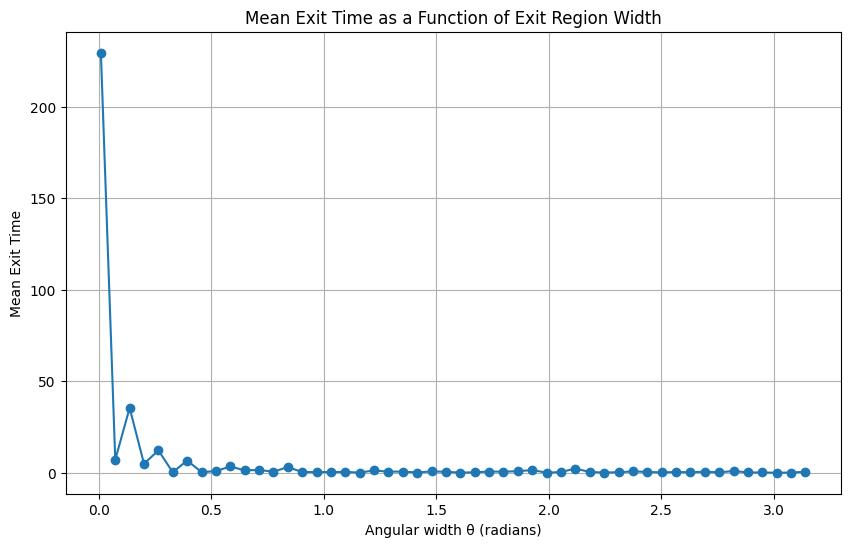

In [96]:
plt.figure(figsize=(10, 6))
plt.plot(thetas, mean_exit_times, marker='o')
plt.xlabel('Angular width θ (radians)')
plt.ylabel('Mean Exit Time')
plt.title('Mean Exit Time as a Function of Exit Region Width')
plt.grid(True)
plt.show()

For very small θ values, the mean exit time is extremely high. This indicates that when the exit region is very narrow, particles take a significantly longer time to escape.

As θ increases to around 0.5 radians, the exit time drops dramatically, suggesting that a moderately wide exit region greatly enhances the escape efficiency.

The stabilization of mean exit times at low values indicates that the variation in the radius has less impact once the exit region width is sufficiently wide. The initial high mean exit times for very small θ values suggest that a smaller radius can exacerbate the difficulty of escaping through narrow regions, leading to higher exit times.

In [97]:
# function to compute mean exit times and confidence intervals
def compute_exit_times(thetas, radii, num_simulations, D, dt):
    results = {}
    for r in radii:
        mean_exit_times = []
        confidence_intervals = []
        for theta in thetas:
            exit_times = [simulate_exit_time(r, theta, D, dt) for _ in range(num_simulations)]
            mean_exit_time = np.mean(exit_times)
            ci = stats.t.interval(0.95, len(exit_times)-1, loc=mean_exit_time, scale=stats.sem(exit_times))
            mean_exit_times.append(mean_exit_time)
            confidence_intervals.append(ci)
        results[r] = {
            'mean_exit_times': mean_exit_times,
            'confidence_intervals': confidence_intervals
        }
    return results

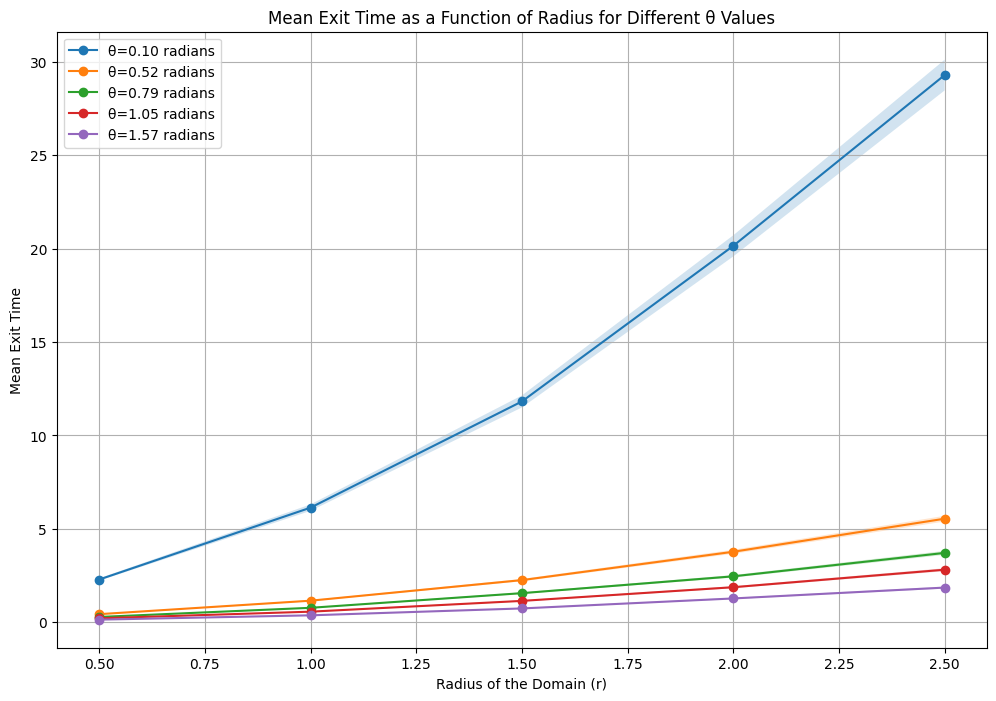

In [98]:
# function to plot the scaling behavior of mean exit times with radius
def plot_scaling_behavior(thetas, radii, results):
    plt.figure(figsize=(12, 8))
    for theta_idx, theta in enumerate(thetas):
        mean_exit_times = [results[r]['mean_exit_times'][theta_idx] for r in radii]
        ci_lower = [results[r]['confidence_intervals'][theta_idx][0] for r in radii]
        ci_upper = [results[r]['confidence_intervals'][theta_idx][1] for r in radii]
        
        plt.plot(radii, mean_exit_times, marker='o', label=f'θ={theta:.2f} radians')
        plt.fill_between(radii, ci_lower, ci_upper, alpha=0.2)
    
    plt.xlabel('Radius of the Domain (r)')
    plt.ylabel('Mean Exit Time')
    plt.title('Mean Exit Time as a Function of Radius for Different θ Values')
    plt.legend()
    plt.grid(True)
    plt.show()

thetas_example = [0.1, np.pi/6, np.pi/4, np.pi/3, np.pi/2]  
radii_example = [0.5, 1.0, 1.5, 2.0, 2.5] 

results_example = compute_exit_times(thetas_example, radii_example, num_simulations, D, dt)

plot_scaling_behavior(thetas_example, radii_example, results_example)

It is observed that, for all θ values, the mean exit time increases as the radius of the domain increases. 

The rate of increase in mean exit time with respect to the radius varies significantly depending on the value of θ.

For smaller radii, the difference in mean exit times between different θ values is minimal. This suggests that for smaller domains, the width of the exit region is less critical.

For larger radii, having a wider exit region significantly reduces the mean exit time compared to a narrow exit region.

## Conclusion ##

This project explored through a thorough analysis the dynamics of Brownian motion within a circular domain, focusing on the relationship between the angular width of the exit region (θ), the domain radius, and the resulting mean exit times. By simulating particle trajectories with varying parameters and analyzing the outcomes, we gained insights into optimizing exit region design to minimize escape times. It was found that there is signficant influence of exit region width and diffusion coefficient on the exit times of particles undergoing Brownian motion and the findings highlight the critical balance between exit region width and particle mobility.